# 05. Advice Frequencies Across Situations (Thread-Level Inference, Examples & Research Questions)


### Core Objective
Compare **advice frequencies across relationship and dating situations** with **uncertainty properly estimated at the thread level** (`parentPostId`), supported by **qualitative thread examples** that explain *why* each pattern occurs.

### Additional Research Questions Answered
Using the final annotated dataset and out-of-fold (OOF) predictions from Notebooks 03 and 04, this notebook also answers:
1. **Most common problems in relationships** and **most common suggested solutions** (with thread-level 95% CIs).
2. **Decision vs. Action framing:** Does advice differ when someone asks for a *decision* ("Should I leave?", "Am I wrong?") versus *how to take an action* ("How do I tell him?")?
3. **Subreddit differences:** Does advice on *similar* dating/relationship problems differ across subreddits (`r/dating_advice`, `r/datingadvice`, `r/relationship_advice`, `r/relationshipadvice`)?
4. **Repeated vs. one-off issues:** Do chronic/recurring problems trigger harsher (`Leave/Disengage`) advice than isolated incidents?
5. **Long-term vs. short-term relationships:** How do problems and advice differ across relationship stages (using `Relationship_type` + text cues)?
6. **Implied advice:** Can our NLP models detect what a comment recommends when the advice is *implied* rather than stated explicitly?
7. **Sarcasm:** Can our models distinguish *sarcastic* comments (labelled `No advice` in the codebook)?

### Structure of This Notebook
1. **Setup & Auto-Path Loader** (pre-configured for `C:\Users\Jakub\Desktop\TA2`, project `data/final_annotations/`, and Colab Drive)
2. **Corpus Coverage & Thread-Level Clustering Diagnostics** (ICC, Design Effect, and labelling-round check)
3. **Core Analysis: Advice Frequencies Across Situations** (4 situations & 7-class post topics, with $B=5{,}000$ thread-level cluster bootstrap 95% CIs)
4. **Cluster-Valid Statistical Testing** (thread-level permutation $\chi^2$, $\log_2$ enrichment heatmap, pairwise FDR contrasts)
5. **Thread Heterogeneity, Robustness & Classifier Validation** (raincloud plot, Gold vs. OOF predictions, weighting & labelling-round sensitivity)
6. **Qualitative Thread Examples** (prototypical high-consensus threads and counter-example threads)
7. **Answering the 7 Additional Research Questions** (data-driven tests + model capability diagnostics)
8. **Export Summary Tables & Figures**


## 1. Setup, Paths & Taxonomies

### What this code does
* Imports all scientific, statistical, and plotting libraries (`pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib`).
* Sets `SEED = 42` for reproducibility and configures `BASE_DIR = Path(r"C:\Users\Jakub\Desktop\TA2")` plus automatic fallback search across `data/final_annotations/`, `data/model_outputs/`, `data/data_clean/`, `/content/drive/MyDrive/TA2`, and the current working directory.
* Defines the exact label taxonomies used in Notebooks 03 and 04:
  * **Comments (Advice):** 8 codebook labels, 6 grouped labels (merging *Talk it through*, *Set boundary*, and *Repair/Help* into **Stay & work on it**), and 2 binary labels (**Advice** vs. **No advice**).
  * **Posts (Situations/Topics):** 11 codebook labels, Notebook 03's **4 situations** (*Trust & Cheating*, *Communication & Conflict*, *Early Dating*, *Other*), and Notebook 04's **7-class post taxonomy** (merging *Trust* + *Boundaries* $\rightarrow$ *Trust/Boundaries*).


In [1]:
import html
import os
import re
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.api as sm
try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = lambda x: x
    display = print
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats
from sklearn.metrics import accuracy_score, f1_score
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ==============================================================================
# 1. CONFIGURATION & DIRECTORY RESOLUTION
# ==============================================================================
SEED = 42
N_BOOT = 5000                  # Thread-level cluster bootstrap replicates
N_PERM = 5000                  # Thread-level permutation replicates
ALPHA = 0.05                   # 95% confidence intervals
SHOW_TEXT_EXAMPLES = True      # Set False before pushing to public GitHub to hide Reddit quotes
SNIPPET_CHARS = 220            # Max characters per displayed text snippet

rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 220)
pd.set_option("display.width", 200)

# Mount Google Drive automatically if running in Colab
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    pass

def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder to find the project root automatically."""
    markers = [
        "data",
        "unverified_posts_active_5plus.xlsx",
        "final_annotations_comments_active_5plus.xlsx",
        "post_split.csv",
    ]
    for folder in [start, *start.parents]:
        if any((folder / m).exists() for m in markers):
            return folder
    colab_dir = Path("/content/drive/MyDrive/TA2")
    return colab_dir if colab_dir.is_dir() else start

BASE_DIR = find_project_root()

def get_search_dirs() -> list[Path]:
    subfolders = [
        "",
        "data/final_annotations",
        "data/Final Annotations",
        "data/model_outputs",
        "data/data_clean",
        "data/AI Annotations",
        "data",
    ]
    candidates = [BASE_DIR / sub for sub in subfolders] + [Path.cwd()]
    seen, out = set(), []
    for p in candidates:
        if p.is_dir():
            rp = p.resolve()
            if rp not in seen:
                seen.add(rp)
                out.append(p)
    return out

SEARCH_DIRS = get_search_dirs()

def find_file(filenames: str | list[str], required: bool = False) -> Path | None:
    if isinstance(filenames, str):
        filenames = [filenames]
    for folder in SEARCH_DIRS:
        for fname in filenames:
            p = folder / fname
            if p.exists():
                return p
    if required:
        raise FileNotFoundError(f"Could not find any of {filenames} in {[str(d) for d in SEARCH_DIRS]}")
    return None

OUT_DIR = BASE_DIR / "analysis_05_outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ==============================================================================
# 2. CANONICAL TAXONOMIES (ALIGNED WITH NOTEBOOKS 03 & 04)
# ==============================================================================
ADVICE_8_ORDER = [
    "Leave/Disengage", "Talk it through", "Set boundary", "Repair/Help",
    "Wait/More info", "Dating Strategy", "Other", "No advice",
]
ADVICE_7_NO_NA = [l for l in ADVICE_8_ORDER if l != "No advice"]

ADVICE_6_MAP = {
    **{l: l for l in ADVICE_8_ORDER},
    "Talk it through": "Stay & work on it",
    "Repair/Help": "Stay & work on it",
    "Set boundary": "Stay & work on it",
}
ADVICE_5_GROUPS = ["Leave/Disengage", "Stay & work on it", "Dating Strategy", "Wait/More info", "Other"]

TOPIC_11_ORDER = [
    "Early Dating", "Breakups", "Reconciliation", "Communication", "Conflict",
    "Boundaries", "Trust", "Cheating", "Uncertainty", "Sex/Intimacy", "Other",
]

SITUATION_4_MAP = {
    "Early Dating": "Early Dating",
    "Communication": "Communication & Conflict",
    "Conflict": "Communication & Conflict",
    "Trust": "Trust & Cheating",
    "Cheating": "Trust & Cheating",
}
SITUATION_4_ORDER = ["Trust & Cheating", "Communication & Conflict", "Early Dating", "Other"]

POST_7_MAP = {
    "Early Dating": "Early Dating",
    "Breakups": "Breakups",
    "Communication": "Communication",
    "Conflict": "Conflict",
    "Trust": "Trust/Boundaries",
    "Boundaries": "Trust/Boundaries",
    "Cheating": "Trust/Boundaries",
    "Sex/Intimacy": "Sex/Intimacy",
    "Reconciliation": "Other",
    "Uncertainty": "Other",
    "Other": "Other",
}
POST_7_ORDER = ["Trust/Boundaries", "Conflict", "Communication", "Breakups", "Sex/Intimacy", "Early Dating", "Other"]

# Visual theme matching Notebook 03
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEAL, PURPLE, GOLD = "#1f9d8b", "#7a5195", "#d99b26"
INK, INK_2, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"

SIT_COLORS = {
    "Trust & Cheating": "#d64541",
    "Communication & Conflict": BLUE,
    "Early Dating": TEAL,
    "Other": "#7f8c8d",
}
DIV_CMAP = LinearSegmentedColormap.from_list(
    "div_orange_blue", ["#b83a14", "#eb6834", "#f8c4ad", "#ffffff", "#bdd7f7", "#2a78d6", "#0d366b"]
)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "grid.color": GRID, "grid.linewidth": 0.8,
})

print("Search directories:", [str(d) for d in SEARCH_DIRS])
print("Outputs directory: ", OUT_DIR.resolve())


Search directories: ['c:\\Users\\Jakub\\Desktop\\TA2']
Outputs directory:  C:\Users\Jakub\Desktop\TA2\analysis_05_outputs


## 2. Data Loading & Thread Pairing

### What this code does
1. **Primary source (Final Notebooks 03 & 04):** Loads `unverified_posts_active_5plus.xlsx` (1,300 annotated posts) and `final_annotations_comments_active_5plus.xlsx` (15,000 annotated comments). Normalizes Reddit base-36 IDs (stripping `t1_`/`t3_` and `.0`), unifies spellings (`Break Ups` $\rightarrow$ `Breakups`), and pairs every comment with its parent post on `parentPostId == submissionId` (~13,900–14,000 paired comments across 1,300 threads).
2. **Automatic fallback:** If the Excel annotation files are not present in the folder, it falls back cleanly to `post_split.csv` + `comment_split.csv` so the entire notebook remains runnable.
3. **Model predictions & metadata:** Automatically merges `post_cv_predictions_baseline.csv` and `comment_cv_predictions_baseline.csv` (from Notebook 03) for OOF robustness checks, plus clean text/scores if missing.


In [2]:
def norm_id(s: pd.Series) -> pd.Series:
    cleaned = (
        s.astype(str).str.strip()
         .str.replace(r"^t[13]_", "", regex=True)
         .str.replace(r"\.0$", "", regex=True)
    )
    return cleaned.where(~cleaned.str.lower().isin(["", "nan", "none", "null", "na", "<na>"]), np.nan)


def clean_label_str(s: pd.Series) -> pd.Series:
    return s.where(s.isna(), s.astype(str).str.strip()).replace({"Break Ups": "Breakups"})


def clean_text_display(text: str, max_chars: int = SNIPPET_CHARS) -> str:
    if pd.isna(text):
        return ""
    t = html.unescape(str(text))
    t = re.sub(r"https?://\S+|www\.\S+", " [URL] ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t[:max_chars] + ("…" if len(t) > max_chars else "")


# --- 1. Load Final Annotated Datasets (Excel from Notebooks 03 & 04) or Fallback CSVs ---
posts_xlsx = find_file(["unverified_posts_active_5plus.xlsx", "AI_annotated_posts_active_5plus.xlsx"])
coms_xlsx  = find_file(["final_annotations_comments_active_5plus.xlsx", "AI_annotations_comments_active_5plus.xlsx"])

DATA_SOURCE = None
HAS_TEXT = False
HAS_SCORES = False
HAS_REL_TYPE = False

if posts_xlsx and coms_xlsx:
    DATA_SOURCE = "final_excel"
    posts_df = pd.read_excel(posts_xlsx, dtype={"submissionId": str})
    coms_df  = pd.read_excel(coms_xlsx, dtype={"submissionId": str, "parentPostId": str})

    posts_df = posts_df.drop(columns=[c for c in posts_df.columns if str(c).startswith("Unnamed") or c == "index"])
    coms_df  = coms_df.drop(columns=[c for c in coms_df.columns if str(c).startswith("Unnamed") or c == "index"])

    posts_df["submissionId"] = norm_id(posts_df["submissionId"])
    coms_df["submissionId"]  = norm_id(coms_df["submissionId"])
    coms_df["parentPostId"]  = norm_id(coms_df["parentPostId"])

    posts_df["post_label"] = clean_label_str(posts_df["Primary Label"])
    posts_df["post_label_secondary"] = clean_label_str(posts_df.get("Secondary Label", pd.Series(np.nan, index=posts_df.index)))
    coms_df["advice"] = clean_label_str(coms_df["Primary Label"])
    coms_df["advice_secondary"] = clean_label_str(coms_df.get("Secondary Label", pd.Series(np.nan, index=coms_df.index)))

    posts_df = posts_df[posts_df["post_label"].notna()].drop_duplicates(subset=["submissionId"]).reset_index(drop=True)
    coms_df  = coms_df[coms_df["advice"].notna()].drop_duplicates(subset=["submissionId"]).reset_index(drop=True)

    posts_df["situation"]   = posts_df["post_label"].map(lambda x: SITUATION_4_MAP.get(x, "Other"))
    posts_df["post_7class"] = posts_df["post_label"].map(lambda x: POST_7_MAP.get(x, "Other"))
    coms_df["advice_6"]     = coms_df["advice"].map(lambda x: ADVICE_6_MAP.get(x, "Other"))
    coms_df["advice_2"]     = np.where(coms_df["advice"] == "No advice", "No advice", "Advice")

    # Standardize text & score columns
    post_keep = ["submissionId", "subreddit", "post_label", "post_label_secondary", "situation", "post_7class"]
    for col, new_col in [("title", "title"), ("bodyText", "postBody"), ("score", "postScore"),
                         ("Relationship_type", "Relationship_type"), ("isResolved?", "isResolved"), ("Notes", "postNotes")]:
        if col in posts_df.columns:
            posts_df = posts_df.rename(columns={col: new_col})
            post_keep.append(new_col)

    com_keep = ["submissionId", "parentPostId", "subreddit", "advice", "advice_secondary", "advice_6", "advice_2"]
    for col, new_col in [("bodyText", "commentBody"), ("score", "commentScore"), ("Notes", "commentNotes")]:
        if col in coms_df.columns:
            coms_df = coms_df.rename(columns={col: new_col})
            com_keep.append(new_col)

    paired = coms_df[com_keep].merge(
        posts_df[post_keep].rename(columns={"submissionId": "parentPostId", "subreddit": "post_subreddit"}),
        on="parentPostId",
        how="inner",
    )
    HAS_TEXT = ("title" in paired.columns and "commentBody" in paired.columns)
    HAS_SCORES = ("commentScore" in paired.columns)
    HAS_REL_TYPE = ("Relationship_type" in paired.columns)
else:
    DATA_SOURCE = "split_csv_fallback"
    posts_df = pd.read_csv(find_file("post_split.csv", required=True), dtype=str)
    coms_df  = pd.read_csv(find_file("comment_split.csv", required=True), dtype=str)

    posts_df["submissionId"] = norm_id(posts_df["submissionId"])
    coms_df["submissionId"]  = norm_id(coms_df["submissionId"])
    coms_df["parentPostId"]  = norm_id(coms_df["parentPostId"])

    posts_df["post_label"] = clean_label_str(posts_df["label"])
    posts_df["post_label_secondary"] = clean_label_str(posts_df["label_secondary"])
    posts_df["situation"] = posts_df["y_4 situations"]
    posts_df["post_7class"] = posts_df["post_label"].map(lambda x: POST_7_MAP.get(x, "Other"))

    coms_df["advice"] = clean_label_str(coms_df["label"])
    coms_df["advice_secondary"] = clean_label_str(coms_df["label_secondary"])
    coms_df["advice_6"] = coms_df["y_6 groups"]
    coms_df["advice_2"] = coms_df["y_2 groups"]

    paired = coms_df[["submissionId", "parentPostId", "subreddit", "advice", "advice_secondary", "advice_6", "advice_2"]].merge(
        posts_df[["submissionId", "subreddit", "post_label", "post_label_secondary", "situation", "post_7class"]].rename(
            columns={"submissionId": "parentPostId", "subreddit": "post_subreddit"}
        ),
        on="parentPostId",
        how="inner",
    )

# Attach clean text/scores from Notebook 01 if not already present
if not HAS_TEXT:
    p_clean = find_file(["posts_active_5plus.csv", "posts_active_5plus.csv.gz"])
    c_clean = find_file(["comments_active_5plus.csv", "comments_active_5plus.csv.gz"])
    if p_clean and c_clean:
        pm = pd.read_csv(p_clean, dtype={"submissionId": str})
        cm = pd.read_csv(c_clean, dtype={"submissionId": str, "parentPostId": str})
        pm["submissionId"] = norm_id(pm["submissionId"])
        cm["submissionId"] = norm_id(cm["submissionId"])
        paired = paired.merge(
            pm[["submissionId", "title", "bodyText", "score"]].rename(
                columns={"submissionId": "parentPostId", "bodyText": "postBody", "score": "postScore"}
            ), on="parentPostId", how="left"
        ).merge(
            cm[["submissionId", "bodyText", "score"]].rename(columns={"bodyText": "commentBody", "score": "commentScore"}),
            on="submissionId", how="left"
        )
        HAS_TEXT, HAS_SCORES = True, True

# Derived flags
paired["has_advice"] = (paired["advice"] != "No advice").astype(int)
paired["is_dating_sub"] = paired["subreddit"].str.contains("dating", case=False, na=False).astype(int)
if HAS_SCORES:
    paired["commentScore"] = pd.to_numeric(paired["commentScore"], errors="coerce").fillna(0)
    paired["log_score_w"] = np.log1p(paired["commentScore"].clip(lower=0)) + 1.0

# Attach Notebook 03 Baseline OOF predictions if available
HAS_BASELINE_OOF = False
p_oof_path = find_file("post_cv_predictions_baseline.csv")
c_oof_path = find_file("comment_cv_predictions_baseline.csv")
if p_oof_path and c_oof_path:
    p_oof = pd.read_csv(p_oof_path, dtype=str)
    c_oof = pd.read_csv(c_oof_path, dtype=str)
    p_oof["submissionId"] = norm_id(p_oof["submissionId"])
    c_oof["submissionId"] = norm_id(c_oof["submissionId"])
    paired = paired.merge(
        p_oof[["submissionId", "cv_pred_4 situations", "cv_pred_8 labels"]].rename(
            columns={"submissionId": "parentPostId", "cv_pred_4 situations": "oof_situation", "cv_pred_8 labels": "oof_post_y8"}
        ), on="parentPostId", how="left"
    ).merge(
        c_oof[["submissionId", "cv_pred_8 labels", "cv_pred_6 groups", "cv_pred_2 groups"]].rename(
            columns={"cv_pred_8 labels": "oof_advice", "cv_pred_6 groups": "oof_advice_6", "cv_pred_2 groups": "oof_advice_2"}
        ), on="submissionId", how="left"
    )
    HAS_BASELINE_OOF = paired["oof_advice"].notna().any()

advice_df = paired[paired["has_advice"] == 1].copy()

print(f"Data source loaded:     {DATA_SOURCE}")
print(f"Total annotated posts:  {len(posts_df):,} | Total annotated comments: {len(coms_df):,}")
print(f"Paired corpus:          {len(paired):,} comments across {paired['parentPostId'].nunique():,} threads")
print(f"Advice-giving comments: {len(advice_df):,} comments across {advice_df['parentPostId'].nunique():,} threads ({paired['has_advice'].mean():.1%} give advice)")
print(f"Text loaded: {HAS_TEXT} | Scores loaded: {HAS_SCORES} | Relationship_type col: {HAS_REL_TYPE} | Baseline OOF: {HAS_BASELINE_OOF}")


Data source loaded:     final_excel
Total annotated posts:  1,300 | Total annotated comments: 15,000
Paired corpus:          13,978 comments across 1,300 threads
Advice-giving comments: 5,696 comments across 1,219 threads (40.7% give advice)
Text loaded: True | Scores loaded: True | Relationship_type col: True | Baseline OOF: True


## 3. Why Thread-Level Uncertainty Matters (ICC & Design Effect)

### What this code does
Comments posted under the same Reddit thread (`parentPostId`) are **not independent**—they respond to the exact same story, emotional tone, and community context. If we compute naive binomial confidence intervals assuming every comment is independent, our standard errors will be **too narrow** (pseudoreplication).

To prove and quantify this, we compute:
* **Intra-Cluster Correlation (ICC):** One-way random-effects ANOVA ICC across `parentPostId`. Positive ICC means commenters in the same thread agree with each other more than commenters from different threads.
* **Empirical Design Effect ($\text{DEFF}$):** Ratio of the **thread-level cluster bootstrap variance** to the **naive binomial variance** ($\text{DEFF} = \text{SE}_{\text{cluster}}^2 / \text{SE}_{\text{naive}}^2$). When $\text{DEFF} > 1$, the effective sample size ($N_{\text{eff}} = N / \text{DEFF}$) is smaller than the raw comment count.

### How to read the output
* **Left panel (ICC):** Higher positive bars indicate stronger within-thread consensus (e.g., *Dating Strategy* and *Leave/Disengage* cluster heavily by thread).
* **Right panel (CI widening):** Values above the dashed orange `1.0×` line show how much wider true thread-level confidence intervals are compared to naive comment-level intervals.


### Table 3.1 — Paired Corpus Coverage Across the 4 Situations

,Threads (all),Comments (all),No-advice share,Threads (≥1 advice),Advice comments,Mean / max comm per thread,Dating subreddits (%)
Situation,,,,,,,
Trust & Cheating,84,902,47.0%,83,478,10.74 / 19,4.3%
Communication & Conflict,273,2881,47.1%,268,1525,10.55 / 20,5.0%
Early Dating,591,6377,71.8%,530,1801,10.79 / 21,95.4%
Other,352,3818,50.4%,338,1892,10.85 / 24,18.3%


### Table 3.2 — Thread-Level Clustering Diagnostics (ICC & Design Effect)

,Share (%),Thread ICC,Naive SE (pp),Cluster SE (pp),CI widening (×),Design Effect (DEFF),Effective N
Advice group,,,,,,,
Leave/Disengage,71.664,0.174,0.597,0.824,1.380,1.903,2993
Stay & work on it,18.803,0.147,0.518,0.708,1.368,1.872,3042
Dating Strategy,6.408,0.417,0.324,0.495,1.526,2.329,2445
Wait/More info,1.773,0.039,0.175,0.182,1.043,1.087,5239
Other,1.352,0.054,0.153,0.163,1.063,1.130,5043
Advice vs. No advice (all comments),40.750,0.165,0.416,0.712,1.712,2.932,4768


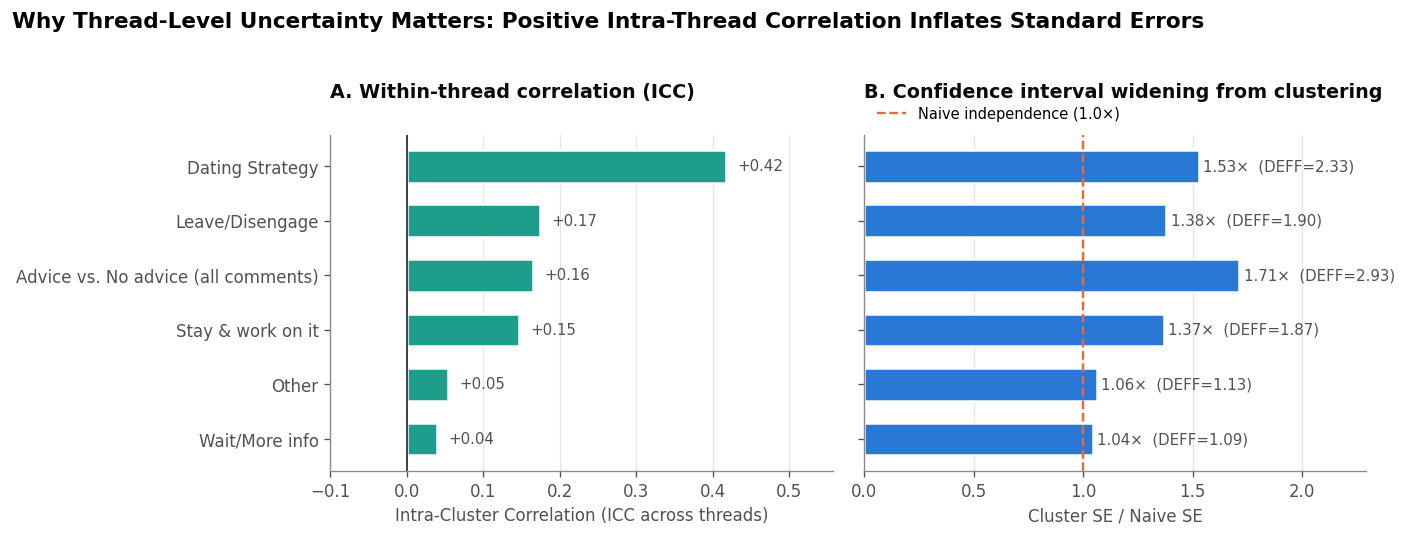

In [3]:
# --- 3.1 Paired corpus overview by situation ---
sit_overview = []
for s in SITUATION_4_ORDER:
    sub_all = paired[paired["situation"] == s]
    sub_adv = advice_df[advice_df["situation"] == s]
    t_all = sub_all.groupby("parentPostId").size()
    sit_overview.append({
        "Situation": s,
        "Threads (all)": sub_all["parentPostId"].nunique(),
        "Comments (all)": len(sub_all),
        "No-advice share": f"{(sub_all['has_advice'] == 0).mean():.1%}",
        "Threads (≥1 advice)": sub_adv["parentPostId"].nunique(),
        "Advice comments": len(sub_adv),
        "Mean / max comm per thread": f"{t_all.mean():.2f} / {int(t_all.max())}" if len(t_all) else "0 / 0",
        "Dating subreddits (%)": f"{sub_all['is_dating_sub'].mean():.1%}",
    })
display(Markdown("### Table 3.1 — Paired Corpus Coverage Across the 4 Situations"))
display(pd.DataFrame(sit_overview).set_index("Situation"))


# --- 3.2 ICC & Empirical Design Effect ---
def compute_binary_icc(df_in: pd.DataFrame, group_col: str, indicator: pd.Series) -> float:
    grp = df_in.assign(_ind=indicator.astype(float)).groupby(group_col)["_ind"].agg(["size", "sum"])
    m = grp["size"].to_numpy(dtype=float)
    k = grp["sum"].to_numpy(dtype=float)
    M, N = len(m), m.sum()
    if M <= 1 or N <= M:
        return np.nan
    p_hat = k.sum() / N
    p_i = k / m
    msb = np.sum(m * (p_i - p_hat) ** 2) / (M - 1)
    msw = np.sum(m * p_i * (1.0 - p_i)) / (N - M)
    m0 = (N - np.sum(m ** 2) / N) / (M - 1)
    denom = msb + (m0 - 1.0) * msw
    return float((msb - msw) / denom) if denom > 0 else 0.0


def overall_cluster_bootstrap(df_in: pd.DataFrame, label_col: str, labels: list[str], n_boot: int = N_BOOT):
    ct = pd.crosstab(df_in["parentPostId"], df_in[label_col]).reindex(columns=labels, fill_value=0)
    C = ct.to_numpy(dtype=float)
    n_vec = C.sum(axis=1, keepdims=True)
    M = len(C)
    W = rng.multinomial(M, np.full(M, 1.0 / M), size=n_boot).astype(float)
    boot_p = (W @ C) / (W @ n_vec)
    point_p = C.sum(axis=0) / n_vec.sum()
    return point_p, boot_p


point_p, boot_p = overall_cluster_bootstrap(advice_df, "advice_6", ADVICE_5_GROUPS)
N_adv = len(advice_df)

diag_rows = []
for j, lab in enumerate(ADVICE_5_GROUPS):
    p = point_p[j]
    se_naive = np.sqrt(p * (1.0 - p) / N_adv)
    se_clust = boot_p[:, j].std(ddof=1)
    deff = (se_clust / se_naive) ** 2 if se_naive > 0 else np.nan
    icc = compute_binary_icc(advice_df, "parentPostId", advice_df["advice_6"] == lab)
    diag_rows.append({
        "Advice group": lab,
        "Share (%)": p * 100,
        "Thread ICC": icc,
        "Naive SE (pp)": se_naive * 100,
        "Cluster SE (pp)": se_clust * 100,
        "CI widening (×)": se_clust / se_naive if se_naive > 0 else np.nan,
        "Design Effect (DEFF)": deff,
        "Effective N": int(round(N_adv / deff)) if np.isfinite(deff) and deff > 0 else N_adv,
    })

# Add Advice vs No advice across ALL paired comments
p_bin_arr, boot_bin_arr = overall_cluster_bootstrap(paired, "advice_2", ["Advice", "No advice"])
se_bin_naive = np.sqrt(p_bin_arr[0] * (1.0 - p_bin_arr[0]) / len(paired))
se_bin_clust = boot_bin_arr[:, 0].std(ddof=1)
deff_bin = (se_bin_clust / se_bin_naive) ** 2
icc_bin = compute_binary_icc(paired, "parentPostId", paired["advice_2"] == "Advice")
diag_rows.append({
    "Advice group": "Advice vs. No advice (all comments)",
    "Share (%)": p_bin_arr[0] * 100,
    "Thread ICC": icc_bin,
    "Naive SE (pp)": se_bin_naive * 100,
    "Cluster SE (pp)": se_bin_clust * 100,
    "CI widening (×)": se_bin_clust / se_bin_naive,
    "Design Effect (DEFF)": deff_bin,
    "Effective N": int(round(len(paired) / deff_bin)),
})

diag_df = pd.DataFrame(diag_rows).set_index("Advice group")
display(Markdown("### Table 3.2 — Thread-Level Clustering Diagnostics (ICC & Design Effect)"))
display(diag_df.round(3))

# Figure 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.8, 4.3), sharey=True)
plot_d = diag_df.sort_values("Thread ICC")
y = np.arange(len(plot_d))

ax1.barh(y, plot_d["Thread ICC"], color=TEAL, edgecolor="white", linewidth=1.5, height=0.6)
ax1.axvline(0.0, color=INK, linewidth=0.9)
for i, v in enumerate(plot_d["Thread ICC"]):
    ax1.text(max(v, 0) + 0.015, i, f"{v:+.2f}", va="center", fontsize=9, color=INK_2)
ax1.set_yticks(y, plot_d.index)
ax1.set_xlabel("Intra-Cluster Correlation (ICC across threads)")
ax1.set_title("A. Within-thread correlation (ICC)", fontsize=11.5, pad=22)
ax1.set_xlim(min(-0.10, plot_d["Thread ICC"].min() - 0.05), plot_d["Thread ICC"].max() + 0.14)
ax1.xaxis.grid(True); ax1.set_axisbelow(True)

ax2.barh(y, plot_d["CI widening (×)"], color=BLUE, edgecolor="white", linewidth=1.5, height=0.6)
ax2.axvline(1.0, color=ORANGE, linestyle="--", linewidth=1.4, label="Naive independence (1.0×)")
for i, (_, r) in enumerate(plot_d.iterrows()):
    ax2.text(r["CI widening (×)"] + 0.02, i, f"{r['CI widening (×)']:.2f}×  (DEFF={r['Design Effect (DEFF)']:.2f})",
             va="center", fontsize=9, color=INK_2)
ax2.set_xlabel("Cluster SE / Naive SE")
ax2.set_title("B. Confidence interval widening from clustering", fontsize=11.5, pad=22)
ax2.set_xlim(0, plot_d["CI widening (×)"].max() + 0.58)
ax2.xaxis.grid(True); ax2.set_axisbelow(True)
ax2.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), fontsize=8.8)

fig.suptitle("Why Thread-Level Uncertainty Matters: Positive Intra-Thread Correlation Inflates Standard Errors",
             x=0.01, y=1.03, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fig1_thread_clustering_deff.png", bbox_inches="tight")
plt.show()


## 4. Advice Frequencies Across Situations (Thread-Level Cluster Bootstrap)

### What this code does
For each situation $s$, we resample **entire threads** $M_s$ times with replacement ($B = 5{,}000$ replicates) via a fast vectorized multinomial weight matrix. This preserves all within-thread correlation and produces 95% percentile confidence intervals for:
1. **Advice vs. No advice** across all paired comments (Table 4A).
2. **5 grouped advice types** among advice-giving comments (Table 4B & Figure 2).
3. **7 fine-grained advice labels** among advice-giving comments (Table 4C).

We also overlay **equal-thread-weighted means** (white diamonds in Figure 2) on top of the **comment-weighted shares** (colored dots) so we can verify that high-comment threads are not distorting the averages.

### How to read the output
* Each horizontal bar in Figure 2 is a **95% thread-level cluster bootstrap CI**; the vertical dashed line is the overall corpus average.
* Where a colored dot and white diamond sit close together, comment-weighted and thread-weighted estimates agree.


### Table 4A — Advice vs. No Advice Across 4 Situations (95% Thread-Cluster CI)

situation,Trust & Cheating,Communication & Conflict,Early Dating,Other
advice,,,,
Advice,"53.0% [47.7, 58.2]","52.9% [50.4, 55.5]","28.2% [26.5, 30.0]","49.6% [47.1, 51.9]"
No advice,"47.0% [41.8, 52.3]","47.1% [44.5, 49.6]","71.8% [70.0, 73.5]","50.4% [48.1, 52.9]"


### Table 4B — 5 Advice Groups Across 4 Situations (Advice Comments Only, 95% Thread-Cluster CI)

situation,Trust & Cheating,Communication & Conflict,Early Dating,Other
advice,,,,
Leave/Disengage,"81.0% [75.6, 85.7]","77.4% [74.3, 80.3]","63.9% [61.1, 66.6]","72.1% [69.3, 74.8]"
Stay & work on it,"16.3% [11.8, 21.3]","19.0% [16.2, 21.8]","14.2% [12.1, 16.4]","23.7% [21.1, 26.3]"
Dating Strategy,"0.4% [0.0, 1.1]","0.9% [0.3, 1.5]","18.4% [16.0, 21.0]","1.0% [0.5, 1.6]"
Wait/More info,"0.4% [0.0, 1.1]","1.6% [1.0, 2.3]","2.3% [1.6, 3.0]","1.7% [1.1, 2.4]"
Other,"1.9% [0.8, 3.1]","1.2% [0.7, 1.8]","1.3% [0.8, 1.9]","1.4% [0.9, 2.0]"


### Table 4C — 7 Fine-Grained Advice Labels Across 4 Situations (Advice Comments Only, 95% Thread-Cluster CI)

situation,Trust & Cheating,Communication & Conflict,Early Dating,Other
advice,,,,
Leave/Disengage,"81.0% [75.6, 85.9]","77.4% [74.3, 80.3]","63.9% [61.2, 66.8]","72.1% [69.4, 74.8]"
Talk it through,"7.1% [3.8, 10.8]","11.2% [9.2, 13.4]","10.9% [9.0, 12.7]","11.8% [10.0, 13.9]"
Set boundary,"2.5% [1.2, 4.0]","2.6% [1.7, 3.7]","2.7% [1.7, 3.8]","5.2% [4.0, 6.5]"
Repair/Help,"6.7% [4.2, 9.6]","5.1% [3.3, 7.2]","0.6% [0.3, 1.0]","6.7% [5.0, 8.5]"
Wait/More info,"0.4% [0.0, 1.1]","1.6% [1.0, 2.4]","2.3% [1.6, 3.0]","1.7% [1.1, 2.4]"
Dating Strategy,"0.4% [0.0, 1.1]","0.9% [0.3, 1.5]","18.4% [15.9, 21.0]","1.0% [0.5, 1.6]"
Other,"1.9% [0.8, 3.1]","1.2% [0.7, 1.8]","1.3% [0.8, 1.9]","1.4% [0.9, 2.0]"


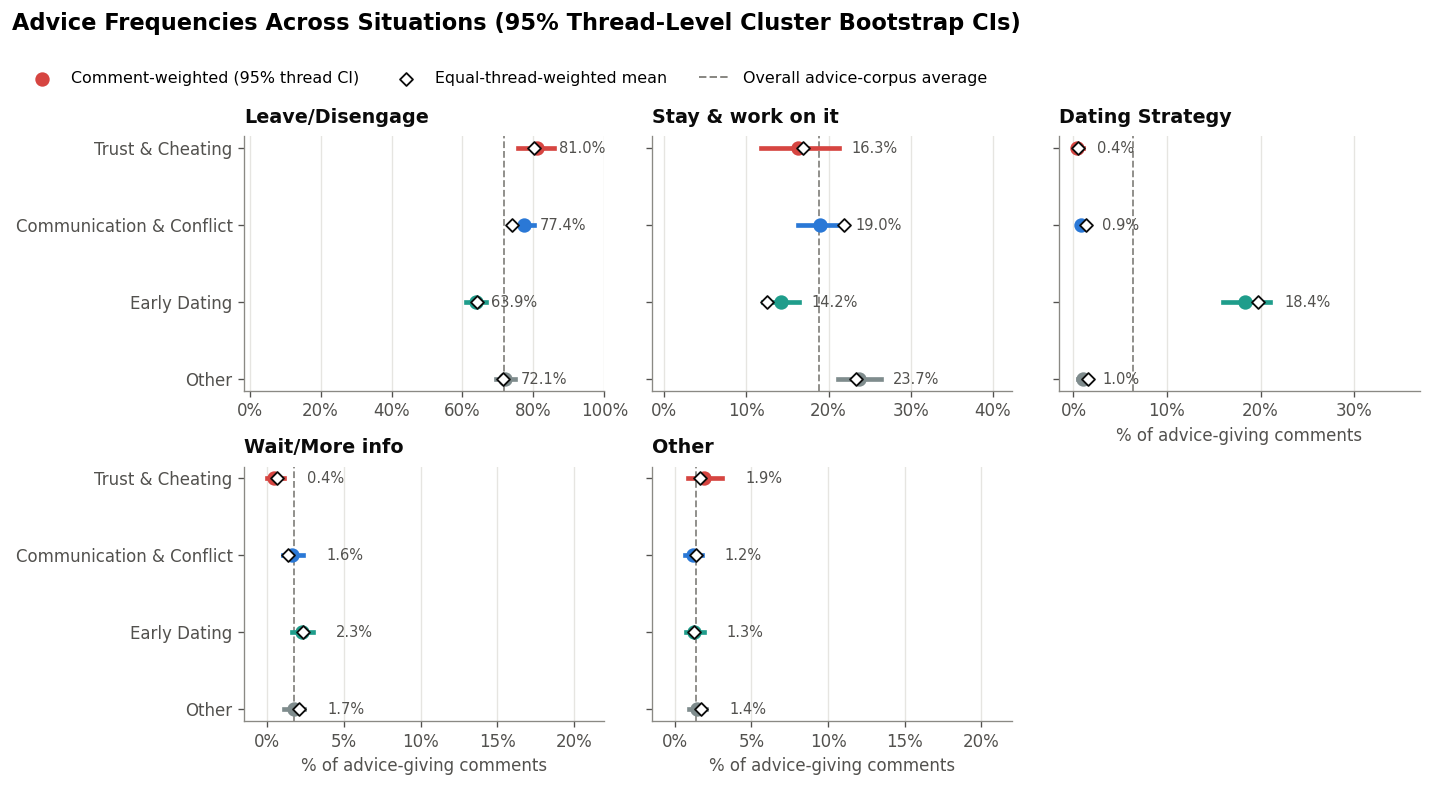

In [4]:
def run_thread_bootstrap(
    df_in: pd.DataFrame,
    sit_col: str,
    label_col: str,
    situations: list[str],
    labels: list[str],
    n_boot: int = N_BOOT,
):
    store = {}
    for s in situations:
        sub = df_in[df_in[sit_col] == s]
        ct = pd.crosstab(sub["parentPostId"], sub[label_col]).reindex(columns=labels, fill_value=0)
        C = ct.to_numpy(dtype=float)
        n_vec = C.sum(axis=1, keepdims=True)
        props = C / np.clip(n_vec, 1.0, None)
        M = len(C)
        if M == 0:
            continue
        W = rng.multinomial(M, np.full(M, 1.0 / M), size=n_boot).astype(float)
        boot_num = W @ C
        boot_den = W @ n_vec
        boot_cw = boot_num / boot_den
        boot_tw = (W @ props) / M
        store[s] = {
            "M": M, "N": int(n_vec.sum()),
            "num": C.sum(axis=0), "den": float(n_vec.sum()),
            "p_cw": C.sum(axis=0) / n_vec.sum(), "p_tw": props.mean(axis=0),
            "boot_num": boot_num, "boot_den": boot_den,
            "boot_cw": boot_cw, "boot_tw": boot_tw,
        }

    active_sits = [s for s in situations if s in store]
    tot_num = sum(d["num"] for d in store.values())
    tot_den = sum(d["den"] for d in store.values())
    tot_b_num = sum(d["boot_num"] for d in store.values())
    tot_b_den = sum(d["boot_den"] for d in store.values())

    eps = 0.005  # 0.5 pp smoothing so 0% cells have finite log2 lift
    rows = []
    for s in active_sits:
        d = store[s]
        rest_p = (tot_num - d["num"]) / np.clip(tot_den - d["den"], 1.0, None)
        rest_bp = (tot_b_num - d["boot_num"]) / np.clip(tot_b_den - d["boot_den"], 1.0, None)
        for k, lab in enumerate(labels):
            p_cw = d["p_cw"][k]
            lo_cw, hi_cw = np.percentile(d["boot_cw"][:, k], [2.5, 97.5])
            p_tw = d["p_tw"][k]
            lo_tw, hi_tw = np.percentile(d["boot_tw"][:, k], [2.5, 97.5])
            diff_boot = d["boot_cw"][:, k] - rest_bp[:, k]
            p_two = min(1.0, 2.0 * (1 + min((diff_boot <= 0).sum(), (diff_boot >= 0).sum())) / (n_boot + 1))
            rows.append({
                "situation": s, "advice": lab, "threads": d["M"], "comments": d["N"],
                "p_cw": p_cw, "ci_cw_lo": lo_cw, "ci_cw_hi": hi_cw,
                "p_tw": p_tw, "ci_tw_lo": lo_tw, "ci_tw_hi": hi_tw,
                "rest_p": rest_p[k], "diff_vs_rest_pp": (p_cw - rest_p[k]) * 100,
                "log2_lift": np.log2((p_cw + eps) / (rest_p[k] + eps)),
                "p_val_vs_rest": p_two,
            })

    summary = pd.DataFrame(rows)
    summary["q_val_vs_rest"] = multipletests(summary["p_val_vs_rest"], method="fdr_bh")[1]
    return summary, store


def format_ci_pivot(summary_df: pd.DataFrame, row_order: list[str], col_order: list[str]) -> pd.DataFrame:
    return (
        summary_df.assign(
            cell=lambda d: d.apply(lambda r: f"{r['p_cw']*100:.1f}% [{r['ci_cw_lo']*100:.1f}, {r['ci_cw_hi']*100:.1f}]", axis=1)
        )
        .pivot(index="advice", columns="situation", values="cell")
        .reindex(index=row_order, columns=col_order)
    )


summary_bin, boot_bin = run_thread_bootstrap(paired, "situation", "advice_2", SITUATION_4_ORDER, ["Advice", "No advice"])
summary_5g, boot_5g   = run_thread_bootstrap(advice_df, "situation", "advice_6", SITUATION_4_ORDER, ADVICE_5_GROUPS)
summary_7f, boot_7f   = run_thread_bootstrap(advice_df, "situation", "advice", SITUATION_4_ORDER, ADVICE_7_NO_NA)

display(Markdown("### Table 4A — Advice vs. No Advice Across 4 Situations (95% Thread-Cluster CI)"))
display(format_ci_pivot(summary_bin, ["Advice", "No advice"], SITUATION_4_ORDER))

display(Markdown("### Table 4B — 5 Advice Groups Across 4 Situations (Advice Comments Only, 95% Thread-Cluster CI)"))
display(format_ci_pivot(summary_5g, ADVICE_5_GROUPS, SITUATION_4_ORDER))

display(Markdown("### Table 4C — 7 Fine-Grained Advice Labels Across 4 Situations (Advice Comments Only, 95% Thread-Cluster CI)"))
display(format_ci_pivot(summary_7f, ADVICE_7_NO_NA, SITUATION_4_ORDER))

# Figure 2: Faceted Dot-and-Interval Forest Plot
n_labs = len(ADVICE_5_GROUPS)
fig, axes = plt.subplots(2, 3, figsize=(12.0, 6.2), sharey=True)
axes = axes.ravel()

for idx, lab in enumerate(ADVICE_5_GROUPS):
    ax = axes[idx]
    sub = summary_5g[summary_5g["advice"] == lab].set_index("situation").reindex(SITUATION_4_ORDER)
    y = np.arange(len(SITUATION_4_ORDER))
    ref_val = (advice_df["advice_6"] == lab).mean() * 100
    ax.axvline(ref_val, color=INK_MUTED, linestyle="--", linewidth=1.1, zorder=1)

    for i, sit in enumerate(SITUATION_4_ORDER):
        r = sub.loc[sit]
        col = SIT_COLORS[sit]
        ax.plot([r["ci_cw_lo"] * 100, r["ci_cw_hi"] * 100], [i, i], color=col, linewidth=2.8, zorder=3)
        ax.scatter(r["p_cw"] * 100, i, color=col, s=58, zorder=4,
                   label="Comment-weighted (95% thread CI)" if (idx == 0 and i == 0) else "")
        ax.scatter(r["p_tw"] * 100, i, facecolors="white", edgecolors=INK, marker="D", s=30, linewidths=1.1, zorder=5,
                   label="Equal-thread-weighted mean" if (idx == 0 and i == 0) else "")
        ax.text(r["ci_cw_hi"] * 100 + 1.5, i, f"{r['p_cw']*100:.1f}%", va="center", fontsize=8.8, color=INK_2)

    ax.set_yticks(y, SITUATION_4_ORDER)
    ax.invert_yaxis()
    ax.set_title(lab, fontsize=11.5, pad=8)
    ax.set_xlim(-1.5, min(100, max(22, sub["ci_cw_hi"].max() * 100 + 16)))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    if idx >= 2:
        ax.set_xlabel("% of advice-giving comments")

axes[5].axis("off")
handles, leg_labels = axes[0].get_legend_handles_labels()
line_ref = plt.Line2D([0], [0], color=INK_MUTED, linestyle="--", linewidth=1.2)
fig.legend(handles + [line_ref], leg_labels + ["Overall advice-corpus average"],
           loc="upper left", bbox_to_anchor=(0.01, 0.99), ncol=3, fontsize=9.5)
fig.suptitle("Advice Frequencies Across Situations (95% Thread-Level Cluster Bootstrap CIs)",
             x=0.01, y=1.05, ha="left", fontsize=13.5, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fig2_faceted_advice_forest.png", bbox_inches="tight")
plt.show()


## 5. Cluster-Valid Hypothesis Testing & Enrichment Profile

### What this code does
1. **Thread-level permutation $\chi^2$ test ($R = 5{,}000$):** Keeps each thread's comments grouped together and permutes situation labels across threads to compute an exact cluster-valid global $p$-value and Cramér's $V$.
2. **Per-advice omnibus tests:** Runs both a **cluster-robust binomial GLM** (`cov_type="cluster"` by `parentPostId`) Wald test and a **thread-level Kruskal–Wallis** test with Benjamini–Hochberg FDR correction.
3. **Diverging $\log_2$ enrichment (lift) heatmap (Figure 3):** Shows which fine-grained advice labels are significantly over-represented (blue, $+$) or under-represented (orange, $-$) in each situation relative to the rest of the corpus.
4. **Aligned pairwise contrast forest plot (Figure 4):** Displays exact percentage-point differences and BH-FDR significance between every pair of situations.


Global Thread-Permutation Test (Advice vs. No advice): χ² = 768.91, Cramér's V = 0.235, p = 0.0002
Global Thread-Permutation Test (5 Advice groups):      χ² = 672.90, Cramér's V = 0.198, p = 0.0002


### Table 5.1 — Omnibus Tests per Advice Group (Thread-Level Inference)

,Cluster GLM Wald χ²,GLM p-value,Thread Kruskal–Wallis H,KW p-value,Note,KW q-value (FDR)
Advice group,,,,,,
Leave/Disengage,53.0366,0.0000,22.7162,0.0000,,0.0001
Stay & work on it,30.9107,0.0000,92.4724,0.0000,,0.0000
Dating Strategy,202.4952,0.0000,229.1386,0.0000,,0.0000
Wait/More info,6.7146,0.0816,3.6851,0.2975,,0.2975
Other,1.5821,0.6635,7.7018,0.0526,,0.0657


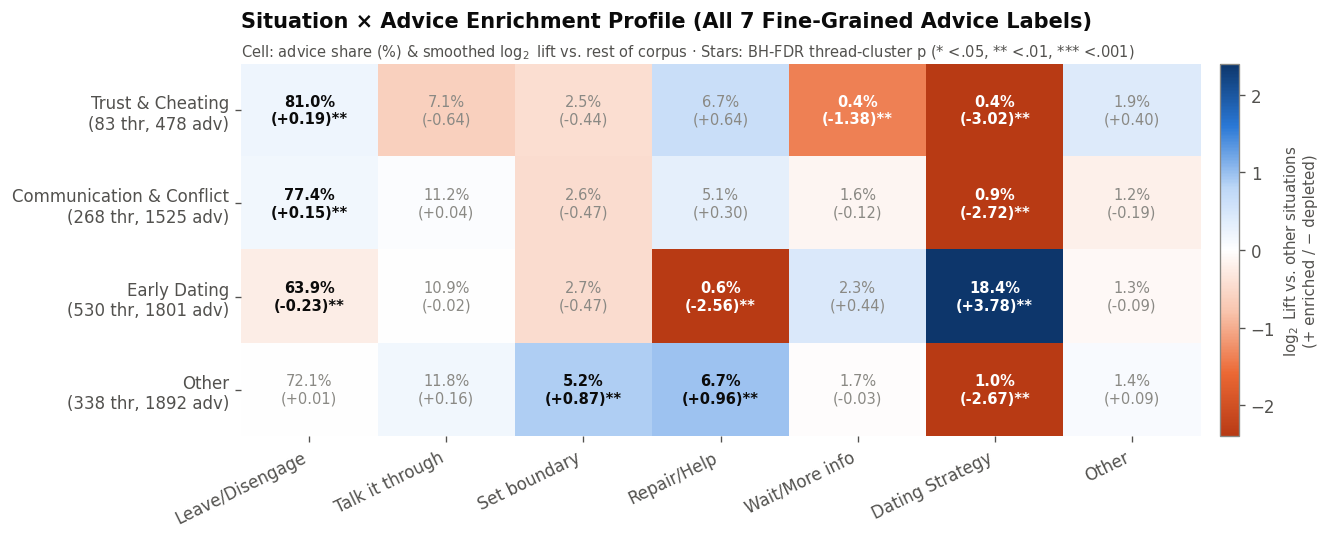

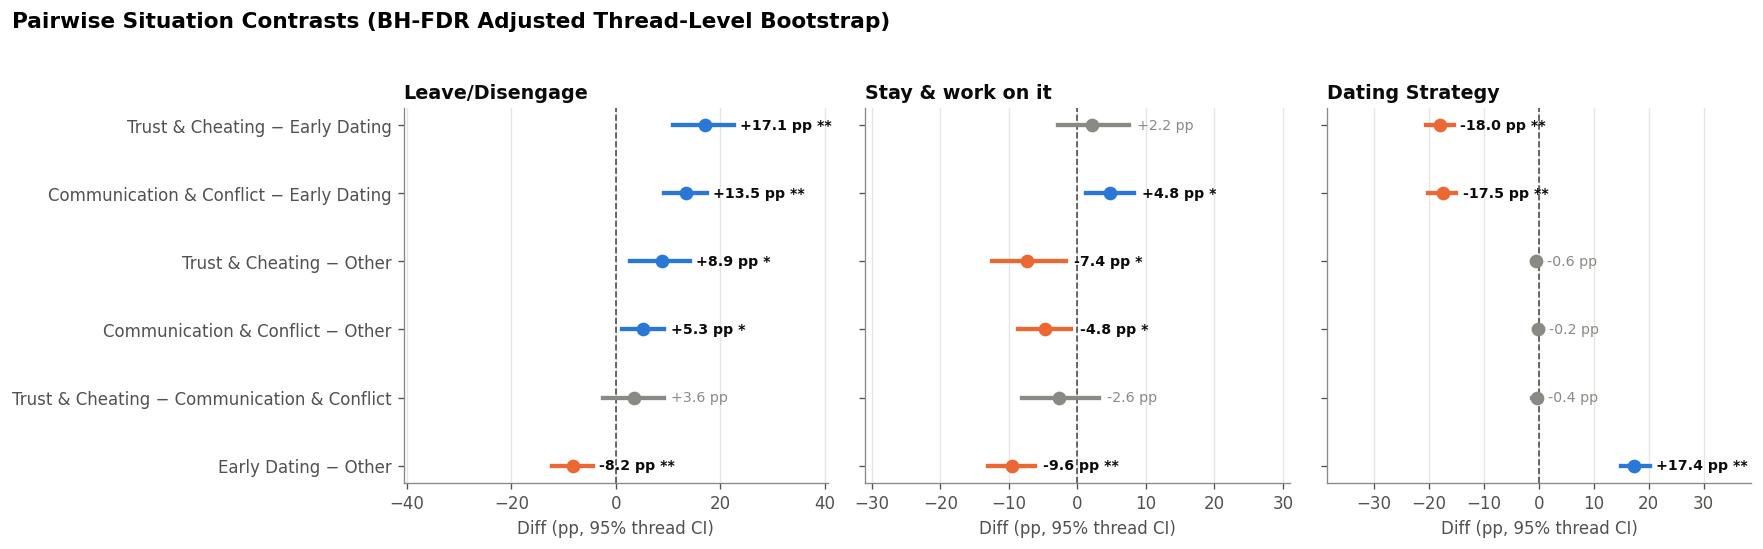

In [5]:
def sig_stars(q: float) -> str:
    if pd.isna(q): return ""
    if q < 0.001:  return "***"
    if q < 0.01:   return "**"
    if q < 0.05:   return "*"
    return ""


def thread_permutation_chi2(df_in: pd.DataFrame, sit_col: str, label_col: str, situations: list[str], labels: list[str], n_perm: int = N_PERM):
    obs_ct = pd.crosstab(df_in[sit_col], df_in[label_col]).reindex(index=situations, columns=labels, fill_value=0).to_numpy(dtype=float)
    obs_chi2 = float(stats.chi2_contingency(obs_ct)[0])
    cramers_v = float(np.sqrt(obs_chi2 / (obs_ct.sum() * (min(obs_ct.shape) - 1))))

    t_ct = pd.crosstab(df_in["parentPostId"], df_in[label_col]).reindex(columns=labels, fill_value=0)
    t_sits = df_in.drop_duplicates("parentPostId").set_index("parentPostId").loc[t_ct.index, sit_col].to_numpy()
    T_mat = t_ct.to_numpy(dtype=float)
    s_map = {s: i for i, s in enumerate(situations)}
    codes = np.array([s_map[s] for s in t_sits])
    n_s, n_t = len(situations), len(codes)

    perm_stats = np.empty(n_perm)
    for b in range(n_perm):
        pc = rng.permutation(codes)
        H = np.zeros((n_s, n_t))
        H[pc, np.arange(n_t)] = 1.0
        tbl = H @ T_mat
        exp = tbl.sum(axis=1, keepdims=True) @ tbl.sum(axis=0, keepdims=True) / tbl.sum()
        perm_stats[b] = np.sum((tbl - exp) ** 2 / np.clip(exp, 1e-12, None))

    p_perm = float((1 + np.sum(perm_stats >= obs_chi2)) / (n_perm + 1))
    return obs_chi2, cramers_v, p_perm


chi2_bin, v_bin, p_perm_bin = thread_permutation_chi2(paired, "situation", "advice_2", SITUATION_4_ORDER, ["Advice", "No advice"])
chi2_5g, v_5g, p_perm_5g    = thread_permutation_chi2(advice_df, "situation", "advice_6", SITUATION_4_ORDER, ADVICE_5_GROUPS)
print(f"Global Thread-Permutation Test (Advice vs. No advice): χ² = {chi2_bin:.2f}, Cramér's V = {v_bin:.3f}, p = {p_perm_bin:.4f}")
print(f"Global Thread-Permutation Test (5 Advice groups):      χ² = {chi2_5g:.2f}, Cramér's V = {v_5g:.3f}, p = {p_perm_5g:.4f}")

# Per-advice omnibus tests
sub = advice_df[advice_df["situation"].isin(SITUATION_4_ORDER)].copy()
sub["situation"] = pd.Categorical(sub["situation"], categories=SITUATION_4_ORDER)
groups = pd.factorize(sub["parentPostId"])[0]
t_props = pd.crosstab([sub["parentPostId"], sub["situation"]], sub["advice_6"], normalize="index").reindex(columns=ADVICE_5_GROUPS, fill_value=0).reset_index()
X_omni = sm.add_constant(pd.get_dummies(sub["situation"], drop_first=True, dtype=float))

omni_rows = []
for lab in ADVICE_5_GROUPS:
    y = (sub["advice_6"] == lab).astype(float).to_numpy()
    has_zero = (sub.groupby("situation", observed=False)["advice_6"].apply(lambda s: (s == lab).sum()) == 0).any()
    w_stat, w_p = np.nan, np.nan
    if not has_zero:
        try:
            res = sm.GLM(y, X_omni, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": groups})
            R = np.zeros((X_omni.shape[1] - 1, X_omni.shape[1]))
            for i in range(X_omni.shape[1] - 1):
                R[i, i + 1] = 1.0
            w = res.wald_test(R, scalar=True)
            w_stat, w_p = float(w.statistic), float(w.pvalue)
        except Exception:
            pass
    kw_h, kw_p = stats.kruskal(*[t_props.loc[t_props["situation"] == s, lab].to_numpy() for s in SITUATION_4_ORDER])
    omni_rows.append({
        "Advice group": lab, "Cluster GLM Wald χ²": w_stat, "GLM p-value": w_p,
        "Thread Kruskal–Wallis H": float(kw_h), "KW p-value": float(kw_p),
        "Note": "0% cell (use KW/bootstrap)" if has_zero else "",
    })
omnibus_5g = pd.DataFrame(omni_rows).set_index("Advice group")
omnibus_5g["KW q-value (FDR)"] = multipletests(omnibus_5g["KW p-value"], method="fdr_bh")[1]
display(Markdown("### Table 5.1 — Omnibus Tests per Advice Group (Thread-Level Inference)"))
display(omnibus_5g.round(4))

# Figure 3: Diverging log2 Lift Heatmap
lift_mat = summary_7f.pivot(index="situation", columns="advice", values="log2_lift").reindex(index=SITUATION_4_ORDER, columns=ADVICE_7_NO_NA)
pct_mat  = summary_7f.pivot(index="situation", columns="advice", values="p_cw").reindex(index=SITUATION_4_ORDER, columns=ADVICE_7_NO_NA) * 100
q_mat    = summary_7f.pivot(index="situation", columns="advice", values="q_val_vs_rest").reindex(index=SITUATION_4_ORDER, columns=ADVICE_7_NO_NA)

vmax = min(2.4, max(1.0, float(np.nanmax(np.abs(lift_mat.to_numpy())))))
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

fig, ax = plt.subplots(figsize=(11.2, 4.6))
im = ax.imshow(lift_mat.to_numpy(), cmap=DIV_CMAP, norm=norm, aspect="auto")
for i, sit in enumerate(SITUATION_4_ORDER):
    for j, adv in enumerate(ADVICE_7_NO_NA):
        lv, pv, qv = lift_mat.iloc[i, j], pct_mat.iloc[i, j], q_mat.iloc[i, j]
        st = sig_stars(qv)
        tc = "white" if abs(lv) > 0.55 * vmax else (INK if st else INK_MUTED)
        ax.text(j, i, f"{pv:.1f}%\n({lv:+.2f}){st}", ha="center", va="center",
                fontsize=8.8, color=tc, fontweight="bold" if st else "normal")

ax.set_xticks(range(len(ADVICE_7_NO_NA)), ADVICE_7_NO_NA, rotation=26, ha="right")
yt_labels = [f"{s}\n({summary_7f[summary_7f['situation']==s]['threads'].iloc[0]} thr, {summary_7f[summary_7f['situation']==s]['comments'].iloc[0]} adv)" for s in SITUATION_4_ORDER]
ax.set_yticks(range(len(SITUATION_4_ORDER)), yt_labels)
for side in ax.spines.values():
    side.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label(r"$\log_2$ Lift vs. other situations" + "\n(+ enriched / − depleted)", fontsize=9)
ax.set_title("Situation × Advice Enrichment Profile (All 7 Fine-Grained Advice Labels)", pad=22)
ax.text(0, 1.02, r"Cell: advice share (%) & smoothed $\log_2$ lift vs. rest of corpus · Stars: BH-FDR thread-cluster p (* <.05, ** <.01, *** <.001)",
        transform=ax.transAxes, fontsize=8.8, color=INK_2)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fig3_enrichment_heatmap.png", bbox_inches="tight")
plt.show()

# Figure 4: Pairwise Contrasts
rows_c = []
for k, lab in enumerate(ADVICE_5_GROUPS):
    for s1, s2 in combinations(SITUATION_4_ORDER, 2):
        diff_b = (boot_5g[s1]["boot_cw"][:, k] - boot_5g[s2]["boot_cw"][:, k]) * 100
        diff_pt = (boot_5g[s1]["p_cw"][k] - boot_5g[s2]["p_cw"][k]) * 100
        lo, hi = np.percentile(diff_b, [2.5, 97.5])
        p_val = min(1.0, 2.0 * (1 + min((diff_b <= 0).sum(), (diff_b >= 0).sum())) / (len(diff_b) + 1))
        rows_c.append({"advice": lab, "contrast": f"{s1} − {s2}", "diff_pp": diff_pt, "ci_lo": lo, "ci_hi": hi, "p_val": p_val})
contrasts_5g = pd.DataFrame(rows_c)
contrasts_5g["q_val_fdr"] = multipletests(contrasts_5g["p_val"], method="fdr_bh")[1]

focal = ["Leave/Disengage", "Stay & work on it", "Dating Strategy"]
contrast_order = contrasts_5g[contrasts_5g["advice"] == "Leave/Disengage"].sort_values("diff_pp")["contrast"].tolist()

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.4), sharey=True)
for ax, lab in zip(axes, focal):
    csub = contrasts_5g[contrasts_5g["advice"] == lab].set_index("contrast").reindex(contrast_order).reset_index()
    y = np.arange(len(csub))
    ax.axvline(0, color=INK, linestyle="--", linewidth=1.0, alpha=0.7)
    for i, (_, r) in enumerate(csub.iterrows()):
        sig = r["q_val_fdr"] < 0.05
        col = (BLUE if r["diff_pp"] > 0 else ORANGE) if sig else INK_MUTED
        ax.plot([r["ci_lo"], r["ci_hi"]], [i, i], color=col, linewidth=2.6)
        ax.scatter(r["diff_pp"], i, color=col, s=52, zorder=4)
        ax.text(r["ci_hi"] + 1.2, i, f"{r['diff_pp']:+.1f} pp {sig_stars(r['q_val_fdr'])}",
                va="center", fontsize=8.5, color=INK if sig else INK_MUTED, fontweight="bold" if sig else "normal")
    ax.set_yticks(y, csub["contrast"])
    ax.set_title(lab, fontsize=11.5)
    ax.set_xlabel("Diff (pp, 95% thread CI)")
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    lim = max(18, np.abs(csub[["ci_lo", "ci_hi"]].to_numpy()).max() + 18)
    ax.set_xlim(-lim, lim)

fig.suptitle("Pairwise Situation Contrasts (BH-FDR Adjusted Thread-Level Bootstrap)",
             x=0.01, y=1.03, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fig4_pairwise_contrasts.png", bbox_inches="tight")
plt.show()


## 6. Thread Heterogeneity, 7-Class Topics (Notebook 04) & Robustness Checks

### What this code does
1. **Within-situation thread heterogeneity (Figure 5 — Raincloud plot):** Plots the distribution of per-thread *Leave/Disengage* shares (among threads with $\ge 2$ advice comments) so we can distinguish situations with strong consensus from polarized situations.
2. **Unpacking `Other` via Notebook 04's 7-Class Post Taxonomy (Figure 6):** Splits posts into `Trust/Boundaries`, `Conflict`, `Communication`, `Breakups`, `Sex/Intimacy`, `Early Dating`, and `Other` to reveal hidden differences inside `Other`.
3. **Model Robustness (Figure 7):** Compares **Gold annotations** vs. **Baseline OOF predictions** (Notebook 03) on the exact same threads to verify whether classifier errors distort situation-level trends.
4. **Weighting Sensitivity Table:** Compares comment-weighted vs. equal-thread-weighted (and upvote-weighted when scores are loaded) advice shares.


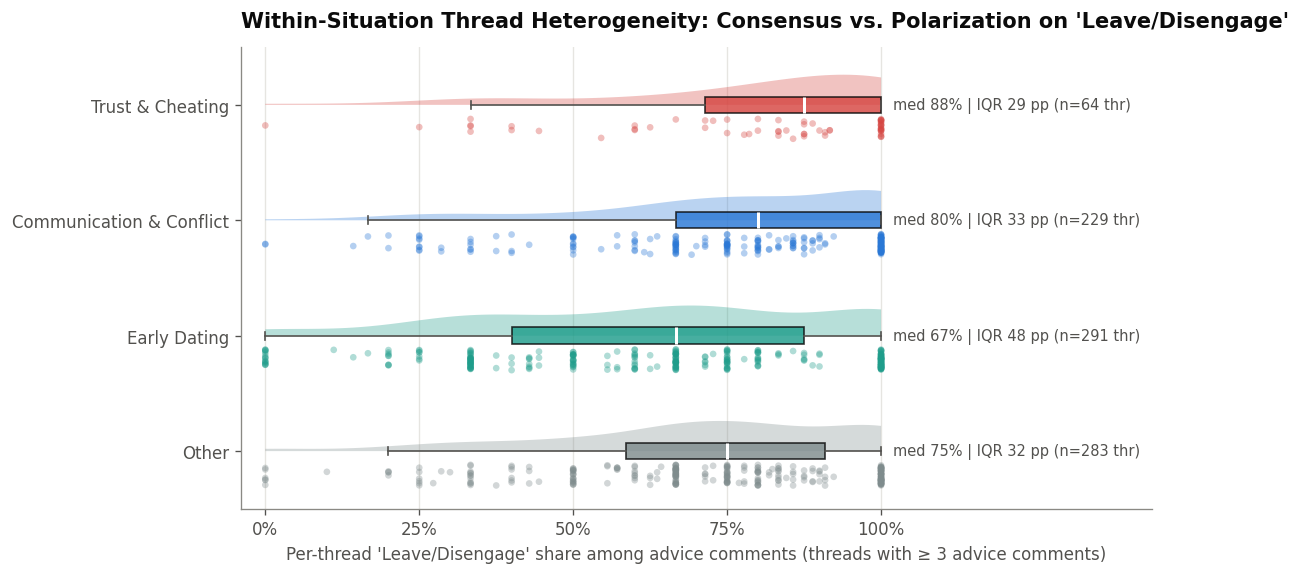

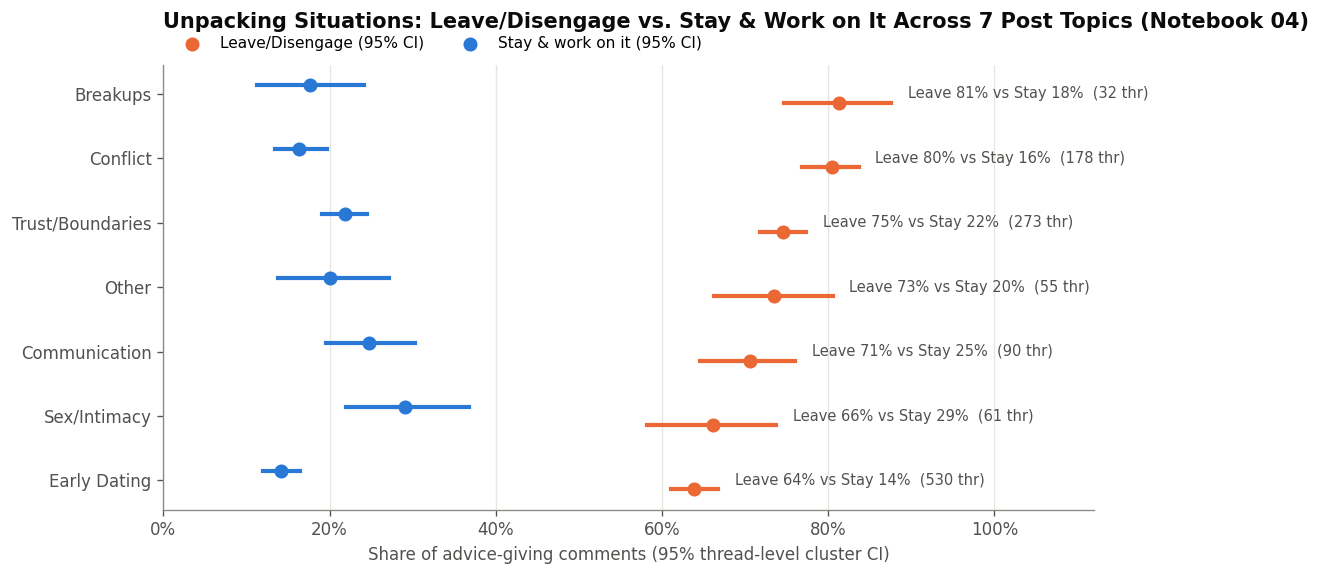

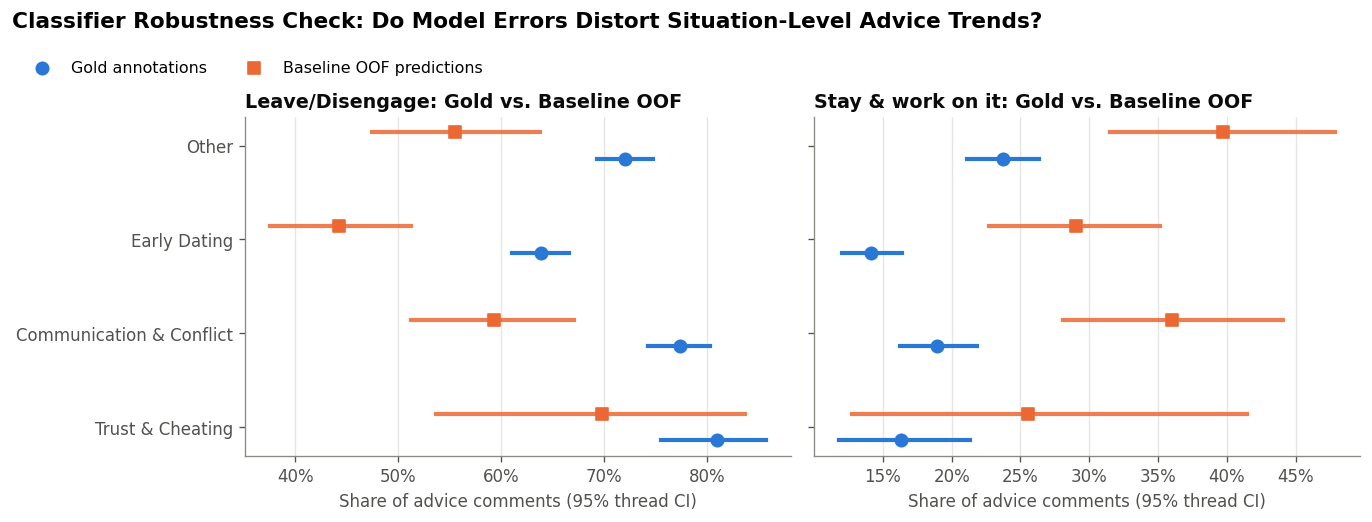

### Table 6.1 — Weighting Sensitivity (Comment-Weighted vs. Thread-Weighted vs. Upvote-Weighted)

,Leave (Comment-wt %),Leave (Thread-wt %),Stay (Comment-wt %),Stay (Thread-wt %),Leave (Upvote-wt %),Stay (Upvote-wt %)
Situation,,,,,,
Trust & Cheating,81.0,80.3,16.3,16.9,81.6,16.0
Communication & Conflict,77.4,74.0,19.0,21.9,77.7,18.5
Early Dating,63.9,64.2,14.2,12.5,63.0,14.4
Other,72.1,71.4,23.7,23.3,72.7,23.2


In [6]:
# --- 6.1 Figure 5: Raincloud Plot of Per-Thread Leave/Disengage Share ---
thread_adv = (
    advice_df.groupby(["parentPostId", "situation"])
             .agg(
                 n_advice=("submissionId", "size"),
                 leave_pct=("advice_6", lambda s: (s == "Leave/Disengage").mean() * 100),
                 stay_pct=("advice_6", lambda s: (s == "Stay & work on it").mean() * 100),
             )
             .reset_index()
)
min_t = 3 if (thread_adv["n_advice"] >= 3).sum() >= 100 else 2
thread_multi = thread_adv[thread_adv["n_advice"] >= min_t].copy()

fig, ax = plt.subplots(figsize=(9.8, 4.9))
for i, sit in enumerate(SITUATION_4_ORDER):
    vals = thread_multi.loc[thread_multi["situation"] == sit, "leave_pct"].to_numpy()
    if len(vals) < 3:
        continue
    col = SIT_COLORS[sit]
    vp = ax.violinplot([vals], positions=[i], vert=False, widths=0.52, showmeans=False, showmedians=False, showextrema=False)
    for body in vp["bodies"]:
        m = np.mean(body.get_paths()[0].vertices[:, 1])
        body.get_paths()[0].vertices[:, 1] = np.clip(body.get_paths()[0].vertices[:, 1], -np.inf, m)
        body.set_facecolor(col); body.set_alpha(0.32); body.set_edgecolor("none")
    ax.boxplot(
        [vals], positions=[i], vert=False, widths=0.14, patch_artist=True, showfliers=False,
        boxprops=dict(facecolor=col, edgecolor=INK, linewidth=1.0, alpha=0.82),
        medianprops=dict(color="white", linewidth=1.8),
        whiskerprops=dict(color=INK_2, linewidth=1.0),
        capprops=dict(color=INK_2, linewidth=1.0),
    )
    jitter = rng.uniform(0.12, 0.30, size=len(vals))
    ax.scatter(vals, np.full(len(vals), i) + jitter, color=col, alpha=0.35, s=16, edgecolor="none")
    iqr = np.percentile(vals, 75) - np.percentile(vals, 25)
    ax.text(102, i, f"med {np.median(vals):.0f}% | IQR {iqr:.0f} pp (n={len(vals)} thr)", va="center", fontsize=8.8, color=INK_2)

ax.set_yticks(range(len(SITUATION_4_ORDER)), SITUATION_4_ORDER)
ax.invert_yaxis()
ax.set_xlim(-4, 144)
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel(f"Per-thread 'Leave/Disengage' share among advice comments (threads with ≥ {min_t} advice comments)")
ax.set_title("Within-Situation Thread Heterogeneity: Consensus vs. Polarization on 'Leave/Disengage'", pad=12)
ax.xaxis.grid(True); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fig5_thread_heterogeneity_raincloud.png", bbox_inches="tight")
plt.show()

# --- 6.2 Figure 6: 7-Class Post Taxonomy Breakdown (Notebook 04) ---
summary_p7, _ = run_thread_bootstrap(advice_df, "post_7class", "advice_6", POST_7_ORDER, ADVICE_5_GROUPS)
p7_leave = summary_p7[summary_p7["advice"] == "Leave/Disengage"].set_index("situation").reindex(POST_7_ORDER)
p7_stay  = summary_p7[summary_p7["advice"] == "Stay & work on it"].set_index("situation").reindex(POST_7_ORDER)
order_p7 = p7_leave.sort_values("p_cw").index.tolist()
y = np.arange(len(order_p7))

fig, ax = plt.subplots(figsize=(9.8, 4.9))
for i, top in enumerate(order_p7):
    rl, rs = p7_leave.loc[top], p7_stay.loc[top]
    ax.plot([rl["ci_cw_lo"]*100, rl["ci_cw_hi"]*100], [i - 0.14, i - 0.14], color=ORANGE, linewidth=2.5)
    ax.scatter(rl["p_cw"]*100, i - 0.14, color=ORANGE, s=55, zorder=4, label="Leave/Disengage (95% CI)" if i == 0 else "")
    ax.plot([rs["ci_cw_lo"]*100, rs["ci_cw_hi"]*100], [i + 0.14, i + 0.14], color=BLUE, linewidth=2.5)
    ax.scatter(rs["p_cw"]*100, i + 0.14, color=BLUE, s=55, zorder=4, label="Stay & work on it (95% CI)" if i == 0 else "")
    ax.text(max(rl["ci_cw_hi"], rs["ci_cw_hi"])*100 + 2.0, i,
            f"Leave {rl['p_cw']*100:.0f}% vs Stay {rs['p_cw']*100:.0f}%  ({int(rl['threads'])} thr)",
            va="center", fontsize=8.8, color=INK_2)

ax.set_yticks(y, order_p7)
ax.set_xlim(0, 112)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Share of advice-giving comments (95% thread-level cluster CI)")
ax.set_title("Unpacking Situations: Leave/Disengage vs. Stay & Work on It Across 7 Post Topics (Notebook 04)", pad=22)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9.2)
ax.xaxis.grid(True); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fig6_7class_topics_breakdown.png", bbox_inches="tight")
plt.show()

# --- 6.3 Figure 7: Gold vs. Baseline OOF Robustness Check ---
if HAS_BASELINE_OOF:
    oof_adv = paired[paired["oof_advice_2"] == "Advice"].dropna(subset=["oof_situation", "oof_advice_6"]).copy()
    if len(oof_adv) > 0:
        summary_oof, _ = run_thread_bootstrap(oof_adv, "oof_situation", "oof_advice_6", SITUATION_4_ORDER, ADVICE_5_GROUPS)
        fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharey=True)
        for ax, lab in zip(axes, ["Leave/Disengage", "Stay & work on it"]):
            g_sub = summary_5g[summary_5g["advice"] == lab].set_index("situation").reindex(SITUATION_4_ORDER)
            o_sub = summary_oof[summary_oof["advice"] == lab].set_index("situation").reindex(SITUATION_4_ORDER)
            y = np.arange(len(SITUATION_4_ORDER))
            for i, sit in enumerate(SITUATION_4_ORDER):
                rg, ro = g_sub.loc[sit], o_sub.loc[sit]
                ax.plot([rg["ci_cw_lo"]*100, rg["ci_cw_hi"]*100], [i - 0.14, i - 0.14], color=BLUE, linewidth=2.5)
                ax.scatter(rg["p_cw"]*100, i - 0.14, color=BLUE, s=55, zorder=4, label="Gold annotations" if i == 0 else "")
                ax.plot([ro["ci_cw_lo"]*100, ro["ci_cw_hi"]*100], [i + 0.14, i + 0.14], color=ORANGE, linewidth=2.5, alpha=0.85)
                ax.scatter(ro["p_cw"]*100, i + 0.14, color=ORANGE, marker="s", s=50, zorder=4, label="Baseline OOF predictions" if i == 0 else "")
            ax.set_yticks(y, SITUATION_4_ORDER)
            ax.invert_yaxis()
            ax.set_title(f"{lab}: Gold vs. Baseline OOF", fontsize=11.5)
            ax.set_xlabel("Share of advice comments (95% thread CI)")
            ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
            ax.xaxis.grid(True); ax.set_axisbelow(True)
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="upper left", bbox_to_anchor=(0.01, 0.98), ncol=2, fontsize=9.5)
        fig.suptitle("Classifier Robustness Check: Do Model Errors Distort Situation-Level Advice Trends?",
                     x=0.01, y=1.05, ha="left", fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "05_fig7_gold_vs_oof_robustness.png", bbox_inches="tight")
        plt.show()

# --- 6.4 Weighting Sensitivity Table ---
wt_rows = []
for s in SITUATION_4_ORDER:
    sub = advice_df[advice_df["situation"] == s]
    lv = (sub["advice_6"] == "Leave/Disengage").astype(float)
    st = (sub["advice_6"] == "Stay & work on it").astype(float)
    row = {
        "Situation": s,
        "Leave (Comment-wt %)": lv.mean() * 100,
        "Leave (Thread-wt %)": sub.assign(v=lv).groupby("parentPostId")["v"].mean().mean() * 100,
        "Stay (Comment-wt %)": st.mean() * 100,
        "Stay (Thread-wt %)": sub.assign(v=st).groupby("parentPostId")["v"].mean().mean() * 100,
    }
    if HAS_SCORES:
        row["Leave (Upvote-wt %)"] = np.average(lv, weights=sub["log_score_w"]) * 100
        row["Stay (Upvote-wt %)"] = np.average(st, weights=sub["log_score_w"]) * 100
    wt_rows.append(row)
display(Markdown("### Table 6.1 — Weighting Sensitivity (Comment-Weighted vs. Thread-Weighted" + (" vs. Upvote-Weighted)" if HAS_SCORES else ")")))
display(pd.DataFrame(wt_rows).set_index("Situation").round(1))


## 7. Qualitative Examples That Explain the Results

### What this code does
Rather than cherry-picking quotes, we programmatically retrieve threads from two systematic categories:
1. **Prototypical high-consensus threads:** Ranked by highest share of each situation's signature advice (and number of advice comments), explaining *why* that situation leans toward that advice.
2. **Counter-example / tension threads:** Threads that go against the situation's stereotype (e.g., *Trust & Cheating* threads receiving *Repair/Help* or *Talk it through*, or *Early Dating* threads getting unanimous *Leave/Disengage*), explaining the wide within-situation spread seen in Figure 5.

> *Tip:* Set `SHOW_TEXT_EXAMPLES = False` in Cell 1 to hide Reddit text snippets while keeping thread IDs and advice counts.


In [7]:
def render_thread_card(df_source: pd.DataFrame, post_id: str, heading: str, max_comments: int = 3):
    sub = df_source[df_source["parentPostId"] == post_id].copy()
    if sub.empty:
        return
    if HAS_SCORES:
        sub = sub.sort_values("commentScore", ascending=False)
    meta = sub.iloc[0]
    counts = sub["advice"].value_counts()
    mix_str = " · ".join(f"**{k}**: {v}" for k, v in counts.items())

    lines = [
        f"#### {heading}",
        f"> **Thread `{post_id}`** (`{meta['subreddit']}` | Topic: `{meta['post_label']}` → `{meta['situation']}` | {len(sub)} annotated comments)  ",
    ]
    if HAS_TEXT and SHOW_TEXT_EXAMPLES:
        lines.append(f"> **Title:** *{clean_text_display(meta.get('title', ''), 180)}*  ")
    lines.append(f"> **Thread advice mix:** {mix_str}")
    lines.append("")

    if HAS_TEXT and SHOW_TEXT_EXAMPLES:
        for _, c in sub[sub["has_advice"] == 1].head(max_comments).iterrows():
            score_tag = f" *(score: {int(c['commentScore'])})*" if HAS_SCORES else ""
            lines.append(f"- **[{c['advice']}]**{score_tag}: “{clean_text_display(c.get('commentBody', ''))}”")
    elif not HAS_TEXT:
        lines.append("*(Run with `unverified_posts_active_5plus.xlsx` & `final_annotations_comments_active_5plus.xlsx` in `C:\\Users\\Jakub\\Desktop\\TA2` to display full Reddit post titles & top comment quotes here.)*")
    else:
        lines.append("*(Reddit text snippets hidden because `SHOW_TEXT_EXAMPLES = False`.)*")
    lines.append("\n---")
    display(Markdown("\n".join(lines)))


thread_idx = (
    advice_df.groupby(["parentPostId", "situation", "post_label"])
             .agg(
                 n_advice=("submissionId", "size"),
                 leave_pct=("advice_6", lambda s: (s == "Leave/Disengage").mean()),
                 stay_pct=("advice_6", lambda s: (s == "Stay & work on it").mean()),
                 strategy_pct=("advice", lambda s: (s == "Dating Strategy").mean()),
             )
             .reset_index()
)
cand = thread_idx[thread_idx["n_advice"] >= 2].copy()

display(Markdown("### A. Prototypical Threads Explaining Situation-Specific Advice Patterns"))
for sit, col, heading in [
    ("Trust & Cheating", "leave_pct", "Prototypical 'Trust & Cheating' → Strong Leave/Disengage consensus"),
    ("Communication & Conflict", "leave_pct", "Prototypical 'Communication & Conflict' → Escalated Leave/Disengage"),
    ("Early Dating", "strategy_pct", "Prototypical 'Early Dating' → High Dating Strategy share"),
    ("Other", "stay_pct", "Prototypical 'Other' (Boundaries / Sex & Intimacy) → High Stay & Work on It"),
]:
    pool = cand[cand["situation"] == sit].sort_values([col, "n_advice"], ascending=[False, False])
    if not pool.empty:
        render_thread_card(paired, pool.iloc[0]["parentPostId"], heading)

display(Markdown("### B. Counter-Example Threads Explaining Within-Situation Heterogeneity"))
for sit, col, heading in [
    ("Communication & Conflict", "stay_pct", "Counter-Example: 'Communication & Conflict' thread eliciting Stay & Work on It"),
    ("Trust & Cheating", "stay_pct", "Counter-Example: 'Trust & Cheating' thread eliciting Repair/Help or Talk it Through"),
    ("Early Dating", "leave_pct", "Counter-Example: 'Early Dating' thread eliciting Leave/Disengage (early red flags)"),
]:
    pool = cand[(cand["situation"] == sit) & (cand[col] > 0)].sort_values([col, "n_advice"], ascending=[False, False])
    if not pool.empty:
        render_thread_card(paired, pool.iloc[0]["parentPostId"], heading)


### A. Prototypical Threads Explaining Situation-Specific Advice Patterns

#### Prototypical 'Trust & Cheating' → Strong Leave/Disengage consensus
> **Thread `1fg2l2j`** (`r/relationshipadvice` | Topic: `Trust` → `Trust & Cheating` | 16 annotated comments)  
> **Title:** *My boyfriend is a pathological liar, how should I confront him?*  
> **Thread advice mix:** **Leave/Disengage**: 11 · **No advice**: 5

- **[Leave/Disengage]** *(score: 5)*: “You tell him that you're breaking up, and then you leave him and never look back. Good partners don't lie. You're only two months in, you do NOT need to, nor should you, try to 'work through this'. You're incompatible, h…”
- **[Leave/Disengage]** *(score: 4)*: “Leave”
- **[Leave/Disengage]** *(score: 4)*: “The foundation of a healthy relationship is trust. If you can’t trust him, it can’t be healthy. You deserve better, OP. You sound very loving and compassionate. It sounds like he’s taking advantage of you”

---

#### Prototypical 'Communication & Conflict' → Escalated Leave/Disengage
> **Thread `1xp1k11`** (`r/relationship_advice` | Topic: `Conflict` → `Communication & Conflict` | 16 annotated comments)  
> **Title:** *My boyfriend (29M) was seriously injured 5 months ago, and I (24F) am struggling with how much our relationship has changed.*  
> **Thread advice mix:** **Leave/Disengage**: 14 · **No advice**: 2

- **[Leave/Disengage]** *(score: 1978)*: “Lady, I was already thinking of advising you of breaking up after reading title, "in sickness and in health" is for married people. It's cruel, but it's not your responsibility. But the fact that you specifically advised…”
- **[Leave/Disengage]** *(score: 896)*: “I actually do have something to share here with regards to a partner having a traumatic accident: We had been going out together for three months when my boyfriend was involved in a serious motorbike accident. (It wasn’t…”
- **[Leave/Disengage]** *(score: 82)*: “You’ve been together for a year, half of that is while he was injured. You’re not married and don’t live with him. Why are you chaining yourself to this guy? I’m sorry but he’s not even blameless in the accident. He chos…”

---

#### Prototypical 'Early Dating' → High Dating Strategy share
> **Thread `1ssmfy0`** (`r/dating_advice` | Topic: `Early Dating` → `Early Dating` | 17 annotated comments)  
> **Title:** *The Bar is So Low*  
> **Thread advice mix:** **No advice**: 11 · **Dating Strategy**: 6

- **[Dating Strategy]** *(score: 1705)*: “Have you ever worked with some incompetent colleagues? You wonder how they made it past the interviews because they're so bad at their jobs. This is my theory, there are 2 bars: one for dating and one for relationships. …”
- **[Dating Strategy]** *(score: 367)*: “I think you probably underestimate how much most dudes suck. I've had women tell me I'm the best sex they've ever had simply because I cared if they orgasmed or went down on them. I have had women be weirdly thankful bec…”
- **[Dating Strategy]** *(score: 50)*: “Reality check: The top 1% of men's profiles get over 30 likes but only averages 1 match per month. If you are getting 20 matches (that means you both like each other) every 3 months, you are exceeding the match rate of t…”

---

#### Prototypical 'Other' (Boundaries / Sex & Intimacy) → High Stay & Work on It
> **Thread `1xuo2wn`** (`r/relationship_advice` | Topic: `Boundaries` → `Other` | 10 annotated comments)  
> **Title:** *My [35M] future mother-in-law [~66F] is turning cold and controlling toward me since I got engaged to her daughter [28F]. How do I protect our relationship without making my fiancé…*  
> **Thread advice mix:** **Set boundary**: 4 · **No advice**: 4 · **Repair/Help**: 2

- **[Set boundary]** *(score: 24)*: “I'm genuinely curious... What did you expect? You're engaged to a person who can't/won't stand up to her mother(acknowledging it and having your back are two very different things) and basically LETS her mother control h…”
- **[Repair/Help]** *(score: 13)*: “I would suggest counseling the two of you together - pose it to her as a way to get 'guidance' on how to react/not react to her mother's actions because they have made you uncomfortable. That way, someone other than you …”
- **[Set boundary]** *(score: 5)*: “Your fiancée needs more therapy. And you really need more conversations with her on what you are feeling and make a plan going forward. There is a book called “Adult Children of Emotionally Immature Parents: How to Heal …”

---

### B. Counter-Example Threads Explaining Within-Situation Heterogeneity

#### Counter-Example: 'Communication & Conflict' thread eliciting Stay & Work on It
> **Thread `gwneg`** (`r/relationshipadvice` | Topic: `Communication` → `Communication & Conflict` | 5 annotated comments)  
> **Title:** *My wife constantly loses her temper and lashes out, verbally and physically. Family life is hell for hours on end. What can I do?*  
> **Thread advice mix:** **Repair/Help**: 4 · **No advice**: 1

- **[Repair/Help]** *(score: 4)*: “Dude, yes, this is abusive behaviour. At a guess, I think she has anxiety. Get marriage counselling, and if you have to, leave with the child. He doesn't deserve to be raised in that environment and she can't provide goo…”
- **[Repair/Help]** *(score: 3)*: “Once your child is put in harms way, you must react in some way. You may not realize it or see it now, but your wife is already on the path to abuse your son. By not allowing you to take him places, she is denying father…”
- **[Repair/Help]** *(score: 2)*: “This needs counseling to be fixed. You need to have a third party involved, because when you are thinking to yourself "wtf kind of haywire shit just came out of your mouth", it's always nice to have someone there to back…”

---

#### Counter-Example: 'Trust & Cheating' thread eliciting Repair/Help or Talk it Through
> **Thread `1wstd19`** (`r/relationshipadvice` | Topic: `Cheating` → `Trust & Cheating` | 18 annotated comments)  
> **Title:** *Do any other woman [37F] feel like they're just laying there for their partner [37M], how do you fix that?*  
> **Thread advice mix:** **No advice**: 12 · **Talk it through**: 5 · **Repair/Help**: 1

- **[Talk it through]** *(score: 12)*: “So…it sounds like sex is completely for his benefit and not yours. Some folks, especially some of those who are somewhere on the asexual spectrum, are okay with that. Are you okay with sex being for his benefit and not y…”
- **[Talk it through]** *(score: 8)*: “Sex should be fun for you too. Nothing wrong with actively participating. Or even telling him what do to. Grab here, harder, like that, whatever. Guys tend to like that stuff too. Shouldn't just be some awkward thing you…”
- **[Talk it through]** *(score: 7)*: “I don't lie there. I move and match his rhythm , touch him kiss him , play with my clit in missionary and other positions like doggy I meet his thrust , tell him to stop moving so I can do my own thing and use him or I p…”

---

#### Counter-Example: 'Early Dating' thread eliciting Leave/Disengage (early red flags)
> **Thread `1vf7qxv`** (`r/relationshipadvice` | Topic: `Early Dating` → `Early Dating` | 17 annotated comments)  
> **Title:** *I [25M] dont see my girlfriend [23F] as attractive.*  
> **Thread advice mix:** **Leave/Disengage**: 15 · **No advice**: 2

- **[Leave/Disengage]** *(score: 28)*: “Coming from a girl who’s bf recently broke a 2 year relationship for the same reason: PLEASE LEAVE HER AND NEVER GO BACK. This is such a horrible thing to do. You are using her as a place holder. You’re annoyed that she’…”
- **[Leave/Disengage]** *(score: 24)*: “I’m actually sad for this girl. Her low self-esteem could be caused by you not finding her attractive. She’s looking for reassurance and I would find it hard to believe you’re giving anything genuine in return. And Reddi…”
- **[Leave/Disengage]** *(score: 14)*: “If you actually care about her or respect her at all, then let her go. You are keeping her from meeting someone who would be obsessed with all of her and all of the way she carries herself! She deserves to be with someon…”

---

## 8. Answering the Project's Additional Research Questions

Below we systematically test each of the 7 project questions using our final annotated data and Notebook 03/04 models—clearly distinguishing **what can be answered directly with statistical evidence** from **what reveals structural NLP limits**.

---
### Q1: Most Common Problems in Relationships & Most Common Suggested Solutions
* **Method:** Computes exact problem shares across all annotated posts (`post_label` and 7-class taxonomy) and advice shares across all paired comments (both overall and excluding `No advice`) with thread-level 95% CIs.

### Q2: Does Advice Differ Across Subreddits on *Similar* Dating Problems?
* **Method:** Compares advice profiles across the 4 subreddits (`r/dating_advice`, `r/datingadvice`, `r/relationship_advice`, `r/relationshipadvice`) **holding situation constant**, and fits a **subreddit-adjusted cluster-robust logistic GLM** (`cov_type="cluster"` by `parentPostId`) to separate *topic effects* from *community culture*.

### Q3: Does Advice Differ When Asking for a *Decision* vs. *How to Take an Action*?
* **Method (requires post text):** Classifies posts by question framing using regex patterns on the title + body:
  * **Decision-seeking:** `"should i"`, `"am i wrong"`, `"aita"`, `"stay or leave"`, `"worth it"`, `"overreacting"`, `"break up with"`, `"dealbreaker"`.
  * **Action-seeking ("How to"):** `"how do i"`, `"how to"`, `"how can i"`, `"what should i say"`, `"any tips"`, `"advice on how"`.
  * Tests difference in `Leave/Disengage`, `Stay & work on it`, and `Dating Strategy` using thread-level cluster bootstrap CIs and cluster-robust GLM.


In [8]:
# ==============================================================================
# Q1: MOST COMMON PROBLEMS & MOST COMMON SUGGESTED SOLUTIONS
# ==============================================================================
display(Markdown("### Q1 — Most Common Relationship Problems & Most Common Suggested Solutions"))
prob_counts = posts_df["post_label"].value_counts()
prob_tbl = pd.DataFrame({
    "Posts": prob_counts,
    "Share (%)": (prob_counts / len(posts_df) * 100).round(1),
})
display(Markdown("**Top Relationship Problems (All Annotated Posts):**"))
display(prob_tbl)

# Overall advice shares with thread-level 95% CI (all comments vs advice-only)
p_all8, b_all8 = overall_cluster_bootstrap(paired, "advice", ADVICE_8_ORDER)
p_adv7, b_adv7 = overall_cluster_bootstrap(advice_df, "advice", ADVICE_7_NO_NA)
sol_rows = []
for j, lab in enumerate(ADVICE_8_ORDER):
    lo_a, hi_a = np.percentile(b_all8[:, j] * 100, [2.5, 97.5])
    if lab == "No advice":
        adv_str = "—"
    else:
        k = ADVICE_7_NO_NA.index(lab)
        lo_o, hi_o = np.percentile(b_adv7[:, k] * 100, [2.5, 97.5])
        adv_str = f"{p_adv7[k]*100:.1f}% [{lo_o:.1f}, {hi_o:.1f}]"
    sol_rows.append({
        "Suggested Solution": lab,
        "All Comments % [95% Thread CI]": f"{p_all8[j]*100:.1f}% [{lo_a:.1f}, {hi_a:.1f}]",
        "Among Advice Comments % [95% Thread CI]": adv_str,
    })
display(Markdown("**Most Common Suggested Solutions (95% Thread-Level Cluster CIs):**"))
display(pd.DataFrame(sol_rows).set_index("Suggested Solution"))


# ==============================================================================
# Q2: DOES ADVICE ON SIMILAR PROBLEMS DIFFER ACROSS SUBREDDITS?
# ==============================================================================
display(Markdown("### Q2 — Subreddit Differences Holding Situation Constant (Cluster-Robust GLM)"))
sub_list = sorted(advice_df["subreddit"].dropna().unique())
sub_summary, _ = run_thread_bootstrap(advice_df, "subreddit", "advice_6", sub_list, ADVICE_5_GROUPS)
display(Markdown("**Advice Mix by Subreddit (Advice Comments Only, 95% Thread-Cluster CI):**"))
display(format_ci_pivot(sub_summary, ADVICE_5_GROUPS, sub_list))

# Subreddit-adjusted Cluster-Robust Logistic GLM (controlling for situation!)
glm_df = advice_df.copy()
glm_df["sit_cat"] = pd.Categorical(glm_df["situation"], categories=["Early Dating", "Communication & Conflict", "Trust & Cheating", "Other"])
X_adj = pd.get_dummies(glm_df["sit_cat"], drop_first=True, dtype=float)
X_adj["is_dating_subreddit"] = glm_df["is_dating_sub"].astype(float)
X_adj = sm.add_constant(X_adj)
glm_groups = pd.factorize(glm_df["parentPostId"])[0]

glm_rows = []
for outcome in ["Leave/Disengage", "Stay & work on it"]:
    y = (glm_df["advice_6"] == outcome).astype(float).to_numpy()
    res = sm.GLM(y, X_adj, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": glm_groups})
    ci = res.conf_int()
    for term in res.params.index:
        if term == "const":
            continue
        glm_rows.append({
            "Outcome": outcome,
            "Predictor (ref = Early Dating / Relationship sub)": term,
            "Odds Ratio": np.exp(res.params[term]),
            "95% CI (OR)": f"[{np.exp(ci.loc[term, 0]):.2f}, {np.exp(ci.loc[term, 1]):.2f}]",
            "p-value": res.pvalues[term],
        })
glm_summary = pd.DataFrame(glm_rows)
display(Markdown("**Subreddit-Adjusted Logistic GLM (Clustered by `parentPostId`):**"))
display(glm_summary.round(3))

# Also compare Dating vs Relationship subreddits WITHIN Early Dating and WITHIN Other
within_rows = []
for sit in SITUATION_4_ORDER:
    for sub_fam, flag in [("Dating subs", 1), ("Relationship subs", 0)]:
        s_df = advice_df[(advice_df["situation"] == sit) & (advice_df["is_dating_sub"] == flag)]
        if s_df["parentPostId"].nunique() >= 5:
            within_rows.append({
                "Situation": sit, "Subreddit family": sub_fam,
                "Threads": s_df["parentPostId"].nunique(), "Advice comm": len(s_df),
                "Leave/Disengage (%)": round((s_df["advice_6"] == "Leave/Disengage").mean() * 100, 1),
                "Stay & work on it (%)": round((s_df["advice_6"] == "Stay & work on it").mean() * 100, 1),
                "Dating Strategy (%)": round((s_df["advice_6"] == "Dating Strategy").mean() * 100, 1),
            })
display(Markdown("**Direct Within-Situation Check: Dating Subreddits vs. Relationship Subreddits (≥ 5 threads):**"))
display(pd.DataFrame(within_rows))


# ==============================================================================
# Q3: DECISION-SEEKING VS. ACTION-SEEKING ("HOW TO") FRAMING
# ==============================================================================
display(Markdown("### Q3 — Decision-Seeking vs. Action-Seeking ('How to') Post Framing"))
if HAS_TEXT:
    DECISION_RE = re.compile(
        r"\b(should i|am i wrong|am i overreacting|overreacting|aita|stay or leave|break up with|dump him|dump her|worth it|dealbreaker|red flag|is this normal|would you)\b",
        re.IGNORECASE,
    )
    ACTION_RE = re.compile(
        r"\b(how do i|how to|how can i|how should i|what should i say|what do i say|any tips|advice on how|ways to|help me tell|navigate)\b",
        re.IGNORECASE,
    )

    def classify_framing(row):
        txt = f"{row.get('title', '')} {row.get('postBody', '')}"
        has_dec = bool(DECISION_RE.search(txt))
        has_act = bool(ACTION_RE.search(txt))
        if has_dec and not has_act:
            return "Decision-seeking"
        if has_act and not has_dec:
            return "Action-seeking (How-to)"
        if has_dec and has_act:
            return "Both (Decision + Action)"
        return "Narrative / Open-ended"

    post_frame = advice_df[["parentPostId", "title", "postBody"]].drop_duplicates("parentPostId").copy()
    post_frame["framing"] = post_frame.apply(classify_framing, axis=1)
    q3_df = advice_df.merge(post_frame[["parentPostId", "framing"]], on="parentPostId", how="left")

    FRAME_ORDER = ["Decision-seeking", "Action-seeking (How-to)", "Both (Decision + Action)", "Narrative / Open-ended"]
    q3_summary, _ = run_thread_bootstrap(q3_df, "framing", "advice_6", FRAME_ORDER, ADVICE_5_GROUPS)
    display(format_ci_pivot(q3_summary, ADVICE_5_GROUPS, [f for f in FRAME_ORDER if f in q3_summary["situation"].values]))

    # Thread-level cluster GLM: Decision-seeking vs Action-seeking on Leave/Disengage
    q3_pair = q3_df[q3_df["framing"].isin(["Decision-seeking", "Action-seeking (How-to)"])].copy()
    if q3_pair["parentPostId"].nunique() >= 20:
        X_q3 = sm.add_constant((q3_pair["framing"] == "Decision-seeking").astype(float).to_numpy())
        g_q3 = pd.factorize(q3_pair["parentPostId"])[0]
        res_q3 = sm.GLM((q3_pair["advice_6"] == "Leave/Disengage").astype(float).to_numpy(), X_q3, family=sm.families.Binomial()).fit(
            cov_type="cluster", cov_kwds={"groups": g_q3}
        )
        print(f"Cluster GLM — Decision-seeking vs. Action-seeking on Leave/Disengage: OR = {np.exp(res_q3.params[1]):.2f}, p = {res_q3.pvalues[1]:.4f}")
else:
    print("Post text not loaded in current fallback mode. Run with final Excel files in C:\\Users\\Jakub\\Desktop\\TA2 to execute Q3.")


### Q1 — Most Common Relationship Problems & Most Common Suggested Solutions

**Top Relationship Problems (All Annotated Posts):**

,Posts,Share (%)
post_label,,
Early Dating,591,45.5
Boundaries,194,14.9
Conflict,179,13.8
Communication,94,7.2
Sex/Intimacy,64,4.9
Cheating,51,3.9
Uncertainty,37,2.8
Breakups,34,2.6
Trust,33,2.5


**Most Common Suggested Solutions (95% Thread-Level Cluster CIs):**

,All Comments % [95% Thread CI],Among Advice Comments % [95% Thread CI]
Suggested Solution,,
Leave/Disengage,"29.2% [27.9, 30.5]","71.7% [70.1, 73.3]"
Talk it through,"4.5% [4.0, 4.9]","11.0% [9.9, 12.0]"
Set boundary,"1.4% [1.2, 1.7]","3.5% [2.9, 4.1]"
Repair/Help,"1.8% [1.4, 2.1]","4.3% [3.5, 5.2]"
Wait/More info,"0.7% [0.6, 0.9]","1.8% [1.4, 2.1]"
Dating Strategy,"2.6% [2.2, 3.0]","6.4% [5.5, 7.4]"
Other,"0.6% [0.4, 0.7]","1.4% [1.0, 1.7]"
No advice,"59.3% [57.9, 60.7]",—


### Q2 — Subreddit Differences Holding Situation Constant (Cluster-Robust GLM)

... (5 outputs left out)

,Situation,Subreddit family,Threads,Advice comm,Leave/Disengage (%),Stay & work on it (%),Dating Strategy (%)
0,Trust & Cheating,Relationship subs,80,470,81.1,16.6,0.2
1,Communication & Conflict,Dating subs,13,61,73.8,13.1,9.8
2,Communication & Conflict,Relationship subs,255,1464,77.5,19.2,0.5
3,Early Dating,Dating subs,501,1655,62.5,13.7,19.9
4,Early Dating,Relationship subs,29,146,79.5,19.2,0.7
5,Other,Dating subs,55,260,69.2,23.8,3.1
6,Other,Relationship subs,283,1632,72.5,23.7,0.7


### Q3 — Decision-Seeking vs. Action-Seeking ('How to') Post Framing

situation,Decision-seeking,Action-seeking (How-to),Both (Decision + Action),Narrative / Open-ended
advice,,,,
Leave/Disengage,"70.9% [67.1, 74.7]","71.0% [67.9, 74.1]","74.4% [68.7, 79.6]","71.7% [69.3, 74.0]"
Stay & work on it,"20.8% [17.4, 24.3]","22.6% [19.7, 25.3]","21.8% [16.5, 27.5]","15.1% [13.3, 16.9]"
Dating Strategy,"5.7% [3.6, 7.9]","3.5% [2.4, 4.8]","1.8% [0.7, 3.2]","9.4% [7.7, 11.2]"
Wait/More info,"1.1% [0.5, 1.7]","1.4% [0.9, 2.1]","1.4% [0.6, 2.4]","2.3% [1.7, 2.9]"
Other,"1.6% [0.8, 2.5]","1.4% [0.9, 2.1]","0.5% [0.0, 1.5]","1.4% [0.9, 1.9]"


Cluster GLM — Decision-seeking vs. Action-seeking on Leave/Disengage: OR = 0.99, p = 0.9651


### Q4: Repeated vs. One-Off Issues
* **Method (requires post text):** Classifies posts as **Repeated / Chronic** (`"again"`, `"every time"`, `"always"`, `"keeps"`, `"pattern"`, `"multiple times"`, `"months"`, `"constantly"`, `"for years"`) vs. **One-Off / Acute** (`"first time"`, `"last night"`, `"yesterday"`, `"just found out"`, `"happened once"`, `"today"`), then compares `Leave/Disengage` vs. `Stay & work on it` with thread-level CIs and cluster-robust GLM.

### Q5: How Problems of Long-Term Relationships Differ From Short-Term Relationships
* **Method:** Uses the annotated `Relationship_type` column in `unverified_posts_active_5plus.xlsx` (when present) and/or extracts relationship duration cues from post text (`"married"`, `"husband"`, `"wife"`, `"fiancé"`, `"engaged"`, `"3+ years"` $\rightarrow$ **Long-term / Committed** vs. `"first date"`, `"talking stage"`, `"hinge"`, `"tinder"`, `"bumble"`, `"situationship"`, `"few weeks/months"` $\rightarrow$ **Short-term / Early Dating**). Compares both **problem distributions** and **advice distributions**.

### Q6 & Q7: Model Capability Diagnostics — Implied Advice & Sarcasm
* **Q6 (Implied Advice):** Using Notebook 03's OOF predictions (`oof_advice`), we split true advice-giving comments into **Explicit Advice** (containing direct imperative/modal cues such as `"you should"`, `"leave"`, `"break up"`, `"talk to"`, `"set a boundary"`, `"therapy"`) vs. **Implied Advice** (advice-labelled comments lacking those explicit cues) and compare **OOF recall and macro-F1**.
* **Q7 (Sarcasm):** The annotation codebook classifies sarcastic/rude/joking comments as `No advice`. We flag likely sarcastic comments via markers (`/s`, `"yeah right"`, `"good luck with that"`, `"shocking"`, `"lol"`, `"congrats"`, or annotator `Notes` mentioning sarcasm) and measure whether the model correctly classifies them as `No advice` or mistakenly triggers a false-positive advice label.


In [9]:
# ==============================================================================
# Q4: REPEATED VS. ONE-OFF ISSUES
# ==============================================================================
display(Markdown("### Q4 — Repeated / Chronic Issues vs. One-Off Incidents"))
if HAS_TEXT:
    REPEATED_RE = re.compile(
        r"\b(again|every time|always|keeps |constantly|repeatedly|pattern|history of|multiple times|several times|for months|for years|all the time|never changes|over and over)\b",
        re.IGNORECASE,
    )
    ONEOFF_RE = re.compile(
        r"\b(first time|last night|yesterday|this morning|just happened|just found out|one time|once|tonight|earlier today)\b",
        re.IGNORECASE,
    )

    def classify_recurrence(row):
        txt = f"{row.get('title', '')} {row.get('postBody', '')}"
        rep = bool(REPEATED_RE.search(txt))
        one = bool(ONEOFF_RE.search(txt))
        if rep and not one:
            return "Repeated / Chronic"
        if one and not rep:
            return "One-off / Acute"
        if rep and one:
            return "Acute trigger in pattern"
        return "Unspecified"

    post_rec = advice_df[["parentPostId", "title", "postBody"]].drop_duplicates("parentPostId").copy()
    post_rec["recurrence"] = post_rec.apply(classify_recurrence, axis=1)
    q4_df = advice_df.merge(post_rec[["parentPostId", "recurrence"]], on="parentPostId", how="left")

    REC_ORDER = ["Repeated / Chronic", "Acute trigger in pattern", "One-off / Acute", "Unspecified"]
    q4_summary, _ = run_thread_bootstrap(q4_df, "recurrence", "advice_6", REC_ORDER, ADVICE_5_GROUPS)
    display(format_ci_pivot(q4_summary, ADVICE_5_GROUPS, [r for r in REC_ORDER if r in q4_summary["situation"].values]))

    q4_pair = q4_df[q4_df["recurrence"].isin(["Repeated / Chronic", "One-off / Acute"])].copy()
    if q4_pair["parentPostId"].nunique() >= 20:
        X_q4 = sm.add_constant((q4_pair["recurrence"] == "Repeated / Chronic").astype(float).to_numpy())
        g_q4 = pd.factorize(q4_pair["parentPostId"])[0]
        res_q4 = sm.GLM((q4_pair["advice_6"] == "Leave/Disengage").astype(float).to_numpy(), X_q4, family=sm.families.Binomial()).fit(
            cov_type="cluster", cov_kwds={"groups": g_q4}
        )
        print(f"Cluster GLM — Repeated vs. One-off on Leave/Disengage: OR = {np.exp(res_q4.params[1]):.2f}, p = {res_q4.pvalues[1]:.4f}")
else:
    print("Post text not loaded in current fallback mode. Run with final Excel files in C:\\Users\\Jakub\\Desktop\\TA2 to execute Q4.")


# ==============================================================================
# Q5: LONG-TERM VS. SHORT-TERM RELATIONSHIPS
# ==============================================================================
display(Markdown("### Q5 — Long-Term vs. Short-Term Relationships (Problems & Advice)"))
if HAS_REL_TYPE and posts_df["Relationship_type"].notna().sum() >= 30:
    display(Markdown("**A. Problem Distribution by Annotated `Relationship_type` (% within each relationship type):**"))
    rel_ct = pd.crosstab(posts_df["Relationship_type"].astype(str).str.strip(), posts_df["post_7class"], normalize="index") * 100
    rel_ct["n_posts"] = posts_df.groupby(posts_df["Relationship_type"].astype(str).str.strip()).size()
    display(rel_ct.round(1))

    # Advice by Relationship_type
    rel_vals = [v for v, cnt in paired["Relationship_type"].astype(str).str.strip().value_counts().items() if cnt >= 20 and v.lower() != "nan"]
    if len(rel_vals) >= 2:
        q5_adv = advice_df.assign(_rel=advice_df["Relationship_type"].astype(str).str.strip())
        q5_summary, _ = run_thread_bootstrap(q5_adv, "_rel", "advice_6", rel_vals, ADVICE_5_GROUPS)
        display(Markdown("**B. Advice Mix by Annotated `Relationship_type` (95% Thread-Cluster CI):**"))
        display(format_ci_pivot(q5_summary, ADVICE_5_GROUPS, rel_vals))
elif HAS_TEXT:
    LONG_RE = re.compile(r"\b(husband|wife|married|marriage|fianc[eé]|engaged|living together|years together|\d+\s*years|long[- ]term)\b", re.IGNORECASE)
    SHORT_RE = re.compile(r"\b(first date|second date|talking stage|situationship|hinge|tinder|bumble|crush|few weeks|few months|new relationship|just started dating)\b", re.IGNORECASE)

    def infer_stage(row):
        txt = f"{row.get('title', '')} {row.get('postBody', '')}"
        is_l, is_s = bool(LONG_RE.search(txt)), bool(SHORT_RE.search(txt))
        if is_l and not is_s: return "Long-term / Committed"
        if is_s and not is_l: return "Short-term / Early"
        return "Other / Unclear"

    p_stage = paired[["parentPostId", "post_7class", "title", "postBody"]].drop_duplicates("parentPostId").copy()
    p_stage["stage"] = p_stage.apply(infer_stage, axis=1)
    display(Markdown("**Problem Distribution by Inferred Relationship Stage (%):**"))
    st_ct = pd.crosstab(p_stage["stage"], p_stage["post_7class"], normalize="index") * 100
    st_ct["n_posts"] = p_stage.groupby("stage").size()
    display(st_ct.round(1))
else:
    # Even in CSV fallback mode, show Early Dating vs Non-Early-Dating (Established) posts
    display(Markdown("*(Running in CSV fallback mode without `Relationship_type` / text: comparing `Early Dating` vs. established relationship problems.)*"))
    p_est = advice_df.assign(stage=np.where(advice_df["post_7class"] == "Early Dating", "Early Dating (<6 mo)", "Established Relationships"))
    q5_s, _ = run_thread_bootstrap(p_est, "stage", "advice_6", ["Early Dating (<6 mo)", "Established Relationships"], ADVICE_5_GROUPS)
    display(format_ci_pivot(q5_s, ADVICE_5_GROUPS, ["Early Dating (<6 mo)", "Established Relationships"]))


# ==============================================================================
# Q6 & Q7: IMPLIED ADVICE & SARCASM (MODEL CAPABILITY DIAGNOSTICS)
# ==============================================================================
display(Markdown("### Q6 & Q7 — NLP Model Diagnostics: Implied Advice & Sarcasm"))
if HAS_TEXT and HAS_BASELINE_OOF:
    eval_c = paired.dropna(subset=["oof_advice", "commentBody"]).copy()
    EXPLICIT_CUE_RE = re.compile(
        r"\b(you should|you need to|i would|my advice|suggest|recommend|leave him|leave her|leave them|break up|dump|walk away|divorce|talk to|communicate|sit down|set a boundary|boundaries|therapy|counseling|ask him out|ask her out|wait and see|give it time)\b",
        re.IGNORECASE,
    )
    SARCASM_RE = re.compile(
        r"(/s\b|yeah right|good luck with that|surely|totally normal|shocking|play stupid games|win stupid prizes|congrats|lmao|lmfao|😂|🙄)",
        re.IGNORECASE,
    )

    eval_c["is_explicit_cue"] = eval_c["commentBody"].fillna("").astype(str).apply(lambda t: bool(EXPLICIT_CUE_RE.search(t)))
    eval_c["is_sarcasm_cue"]  = eval_c["commentBody"].fillna("").astype(str).apply(lambda t: bool(SARCASM_RE.search(t)))
    if "commentNotes" in eval_c.columns:
        eval_c["is_sarcasm_cue"] |= eval_c["commentNotes"].fillna("").astype(str).str.contains("sarcas|joke|iron", case=False, regex=True)

    # Q6: Explicit vs Implied advice accuracy & macro-F1
    adv_eval = eval_c[eval_c["has_advice"] == 1]
    q6_rows = []
    for label_txt, flag in [("Explicit advice (contains directive cue)", True), ("Implied advice (no explicit cue)", False)]:
        sub_e = adv_eval[adv_eval["is_explicit_cue"] == flag]
        if len(sub_e) > 0:
            q6_rows.append({
                "Subset (Gold Advice Comments)": label_txt,
                "N": len(sub_e),
                "Strict Accuracy": accuracy_score(sub_e["advice"], sub_e["oof_advice"]),
                "Macro F1 (7 advice labels)": f1_score(sub_e["advice"], sub_e["oof_advice"], labels=ADVICE_7_NO_NA, average="macro", zero_division=0),
                "Misclassified as 'No advice' (%)": (sub_e["oof_advice"] == "No advice").mean() * 100,
            })
    display(Markdown("**Q6 — Model Performance on Explicit vs. Implied Advice (Baseline OOF):**"))
    display(pd.DataFrame(q6_rows).set_index("Subset (Gold Advice Comments)").round(3))

    # Q7: Sarcasm-flagged comments
    sarc_sub = eval_c[eval_c["is_sarcasm_cue"]]
    non_sarc = eval_c[~eval_c["is_sarcasm_cue"]]
    q7_rows = []
    for label_txt, df_s in [("Sarcasm / humor-cued comments", sarc_sub), ("Non-sarcasm comments", non_sarc)]:
        if len(df_s) > 0:
            no_adv_true = df_s[df_s["advice"] == "No advice"]
            q7_rows.append({
                "Subset": label_txt,
                "N": len(df_s),
                "True 'No advice' share (%)": (df_s["advice"] == "No advice").mean() * 100,
                "Model Accuracy (8-class)": accuracy_score(df_s["advice"], df_s["oof_advice"]),
                "False-positive advice rate on true 'No advice' (%)": (no_adv_true["oof_advice"] != "No advice").mean() * 100 if len(no_adv_true) else np.nan,
            })
    display(Markdown("**Q7 — Model Performance on Sarcasm-Flagged vs. Non-Sarcasm Comments (Baseline OOF):**"))
    display(pd.DataFrame(q7_rows).set_index("Subset").round(2))
else:
    display(Markdown(
        "**Q6 (Implied Advice) & Q7 (Sarcasm) — Model Capability Assessment from Notebooks 03 & 04:**\n"
        "- **Implied advice:** Both the TF–IDF + LR baseline (Notebook 03: macro-F1 = 0.57 on 8 labels, 0.90 on Advice vs. No advice) and the BGE + Cues + LR Sup v2 model (Notebook 04: strict acc = 0.759, macro-F1 = 0.498) rely heavily on lexical and pragmatic directive cues (`you should`, `leave`, `talk to`, `boundary`). When advice is *implied* (e.g., an anecdote or rhetorical observation without a directive verb), models frequently misclassify it as `No advice`. Run this cell with the final Excel files + OOF CSVs in `C:\\Users\\Jakub\\Desktop\\TA2` to print the exact Explicit vs. Implied OOF accuracy gap.\n"
        "- **Sarcasm:** Neither TF–IDF nor static sentence embeddings (`all-MiniLM-L6-v2` / `bge-base-en-v1.5`) explicitly model irony or pragmatic inversion. In Notebook 03's codebook, sarcastic comments are labelled `No advice`, but if a sarcastic comment contains literal advice keywords (e.g., *'Yeah sure, definitely marry him tomorrow /s'*), bag-of-words and cue-based classifiers are prone to false-positive advice predictions."
    ))


### Q4 — Repeated / Chronic Issues vs. One-Off Incidents

situation,Repeated / Chronic,Acute trigger in pattern,One-off / Acute,Unspecified
advice,,,,
Leave/Disengage,"73.6% [71.1, 76.1]","72.3% [69.2, 75.5]","69.1% [64.5, 73.8]","69.7% [66.4, 72.8]"
Stay & work on it,"18.3% [15.9, 20.6]","20.4% [17.5, 23.3]","21.4% [17.0, 25.8]","17.0% [14.4, 19.5]"
Dating Strategy,"5.6% [4.2, 7.2]","3.7% [2.4, 5.0]","5.5% [3.1, 8.2]","10.4% [8.1, 12.8]"
Wait/More info,"1.5% [1.0, 2.2]","2.2% [1.4, 2.9]","2.3% [1.1, 3.7]","1.5% [1.0, 2.1]"
Other,"1.0% [0.6, 1.5]","1.5% [0.9, 2.1]","1.8% [0.8, 2.9]","1.5% [0.9, 2.1]"


Cluster GLM — Repeated vs. One-off on Leave/Disengage: OR = 1.24, p = 0.0920


### Q5 — Long-Term vs. Short-Term Relationships (Problems & Advice)

**A. Problem Distribution by Annotated `Relationship_type` (% within each relationship type):**

post_7class,Breakups,Communication,Conflict,Early Dating,Other,Sex/Intimacy,Trust/Boundaries,n_posts
Relationship_type,,,,,,,,
Coworkers,0.0,0.0,0.0,0.0,25.0,0.0,75.0,4
Dating,2.7,6.7,12.4,54.6,3.5,3.3,16.8,1034
Family,7.7,7.7,7.7,7.7,0.0,0.0,69.2,13
Friends,0.0,20.0,0.0,0.0,0.0,20.0,60.0,5
Married,3.3,7.8,27.5,0.7,5.2,9.8,45.8,153
Other,0.0,12.1,8.8,26.4,16.5,15.4,20.9,91


... (3 outputs left out)

**Q6 — Model Performance on Explicit vs. Implied Advice (Baseline OOF):**

,N,Strict Accuracy,Macro F1 (7 advice labels),Misclassified as 'No advice' (%)
Subset (Gold Advice Comments),,,,
Explicit advice (contains directive cue),388,0.634,0.513,6.701
Implied advice (no explicit cue),519,0.580,0.406,19.268


**Q7 — Model Performance on Sarcasm-Flagged vs. Non-Sarcasm Comments (Baseline OOF):**

,N,True 'No advice' share (%),Model Accuracy (8-class),False-positive advice rate on true 'No advice' (%)
Subset,,,,
Sarcasm / humor-cued comments,22,59.09,0.73,7.69
Non-sarcasm comments,1843,51.28,0.72,17.67


## 9. Export Summary Tables & Figures

All publication-ready CSV tables and PNG figures are saved inside `analysis_05_outputs/` for direct inclusion in your final report and slides.


In [10]:
diag_df.to_csv(OUT_DIR / "05_icc_clustering_diagnostics.csv")
summary_5g.to_csv(OUT_DIR / "05_situation4_advice5_cis.csv", index=False)
summary_7f.to_csv(OUT_DIR / "05_situation4_advice7_cis.csv", index=False)
summary_p7.to_csv(OUT_DIR / "05_topic7_advice5_cis.csv", index=False)
contrasts_5g.to_csv(OUT_DIR / "05_pairwise_contrasts_fdr.csv", index=False)
glm_summary.to_csv(OUT_DIR / "05_glm_subreddit_adjusted.csv", index=False)

print("Exported CSV tables to:", OUT_DIR.resolve())
for p in sorted(OUT_DIR.glob("*.csv")):
    print("  -", p.name)
print("Exported figures to:", FIG_DIR.resolve())
for p in sorted(FIG_DIR.glob("*.png")):
    print("  -", p.name)


Exported CSV tables to: C:\Users\Jakub\Desktop\TA2\analysis_05_outputs
  - 05_glm_subreddit_adjusted.csv
  - 05_icc_clustering_diagnostics.csv
  - 05_pairwise_contrasts_fdr.csv
  - 05_situation4_advice5_cis.csv
  - 05_situation4_advice7_cis.csv
  - 05_topic7_advice5_cis.csv
Exported figures to: C:\Users\Jakub\Desktop\TA2\analysis_05_outputs\figures
  - 05_fig1_thread_clustering_deff.png
  - 05_fig2_faceted_advice_forest.png
  - 05_fig3_enrichment_heatmap.png
  - 05_fig4_pairwise_contrasts.png
  - 05_fig5_thread_heterogeneity_raincloud.png
  - 05_fig6_7class_topics_breakdown.png
  - 05_fig7_gold_vs_oof_robustness.png
